# Atividade computacional: Filtragem de Imagens e Análise de Ruído
**Unidade:** 2 | **Capítulo:** 1 | **Tarefa:** 3


## 1. Introdução

Toda imagem digital carrega alguma degradação: o sensor converte luz em sinal elétrico com flutuações aleatórias, a transmissão pode corromper bits e a compressão descarta informação. Para uma pessoa, uma foto levemente granulada continua legível; para um algoritmo, cada pixel é um número, e o ruído altera exatamente os valores que ele usa para decidir onde há uma borda, uma textura ou um objeto.

A filtragem é a etapa do pipeline que tenta separar o que é **estrutura da cena** do que é **perturbação**. Essa separação nunca é perfeita: ruído e bordas são ambos variações rápidas de intensidade, então remover um tende a atenuar o outro.

Neste notebook, duas imagens do mini-dataset da Unidade 1 — uma da **Classe A (Controle)** e uma da **Classe B (Nintendo Switch)** — recebem ruído gaussiano e ruído sal e pimenta e, em seguida, são filtradas **no domínio da frequência**: a imagem é levada ao espectro pela Transformada de Fourier, multiplicada por uma máscara e devolvida ao domínio do espaço. São testados um filtro passa-baixa gaussiano em dois níveis (kernels 3×3 e 7×7) e um filtro passa-alta Laplaciano, com cada etapa analisada visualmente e comparada entre as classes.

### Preparação do ambiente

Bibliotecas utilizadas: **OpenCV** (leitura, conversão de cor e redimensionamento), **NumPy** (operações matriciais, geração de ruído e FFT), **PIL** (leitura do formato do arquivo, que o OpenCV não informa), **pandas** (tabelas) e **Matplotlib** (visualização).

A semente aleatória é fixada para que o ruído gerado — e, portanto, todas as análises — seja o mesmo a cada execução.

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

drive.mount('/content/drive')
PATH = '/content/drive/MyDrive/dataset'   # pasta com classe_A/ e classe_B/

TAMANHO_TRABALHO = (1024, 768)   # (largura, altura) — mantém a proporção 4:3 do original
SEMENTE = 42                     # semente fixa: cada função de ruído cria seu próprio gerador com ela

plt.rcParams['image.interpolation'] = 'nearest'   # impede o matplotlib de suavizar a exibição

Mounted at /content/drive


## 2. Seleção das imagens

Foram escolhidas duas imagens capturadas **no mesmo cenário** — objeto pequeno e centralizado sobre piso de cerâmica claro. Mantendo fundo, iluminação e enquadramento equivalentes, o **objeto passa a ser a principal variável** entre as classes, e as diferenças observadas nos experimentos podem ser atribuídas a ele com mais segurança.

Informações extraídas de cada imagem:

| Informação | Por que importa |
|---|---|
| Formato do arquivo | JPEG usa compressão com perdas: a imagem já traz artefatos antes do ruído artificial |
| Resolução original | Tamanho real da captura |
| Resolução de trabalho | É nela que os kernels atuam (ver 2.3) |
| Tamanho do arquivo | Indica o grau de compressão |
| Modo de cor / bits | 8 bits por canal → faixa 0–255, limite em que o ruído será cortado |
| Média e desvio padrão (cinza) | Linha de base para medir o efeito do ruído e dos filtros |

### 2.1 Classe A — Controle (`img001_original.jpg`)

Controle de videogame preto sobre piso de cerâmica claro com veios de mármore.

| Parâmetro | Valor |
|---|---|
| Aparelho | Samsung Galaxy A34 5G |
| Arquivo original | `20260906_143650.heic` (378 KB) — convertido para JPEG |
| Cenário | Piso de cerâmica claro com veios de mármore; objeto centralizado, vista de cima |
| ISO | 100 |
| Velocidade do obturador | 1/60 s |
| Abertura | f/1.8 |
| Distância focal | 25 mm (equivalente) |
| Compensação de exposição | 0,0 EV |

### 2.2 Classe B — Nintendo Switch (`img006_original.jpg`)

Console Nintendo Switch com Joy-Cons estampados, sobre o mesmo piso de cerâmica.

| Parâmetro | Valor |
|---|---|
| Aparelho | Samsung Galaxy A34 5G |
| Arquivo original | `20260906_143639.heic` (356 KB) — convertido para JPEG |
| Cenário | Mesmo piso de cerâmica da Classe A; objeto centralizado, vista de cima |
| ISO | 125 |
| Velocidade do obturador | 1/60 s |
| Abertura | f/1.8 |
| Distância focal | 25 mm (equivalente) |
| Compensação de exposição | 0,0 EV |

> Dados consultados na galeria do celular, pois o EXIF foi perdido na conversão HEIC → JPG. As duas fotos foram tiradas com 11 segundos de diferença, com obturador, abertura e distância focal idênticos — as condições de captura são praticamente as mesmas.

### 2.3 Carregamento e ficha técnica

As fotos originais têm 8000×6000 px (48 MP). Trabalhar nessa resolução traria dois problemas: a FFT de uma imagem de 48 MP ocupa cerca de 770 MB por matriz complexa, e um kernel 3×3 cobriria uma fração ínfima da cena, tornando a comparação entre 3×3 e 7×7 praticamente invisível.

Por isso, as imagens são **redimensionadas para 1024×768** com `cv2.INTER_AREA` (método indicado para reduções, pois calcula a média por área e evita serrilhado). O redimensionamento suaviza a imagem, mas isso **não compromete o experimento**: o ruído estudado é artificial e será inserido *depois*, sobre a imagem já reduzida — que passa a ser a "original" de referência.

O processamento é feito em **escala de cinza**, pois a FFT 2D opera sobre um único canal; a versão colorida é mantida apenas para exibição.

In [ ]:
selecao = [
    ('img001_original.jpg', 'A', 'Controle'),
    ('img006_original.jpg', 'B', 'Nintendo Switch'),
]

imagens = {}     # cinza, 1024x768 — usada em todos os experimentos
coloridas = {}   # colorida, 1024x768 — apenas para exibição
fichas = []

for nome, classe, objeto in selecao:
    caminho = os.path.join(PATH, f'classe_{classe}', nome)

    # metadados do arquivo (o PIL informa o formato; o OpenCV não)
    with Image.open(caminho) as pil:
        formato, modo, (w0, h0) = pil.format, pil.mode, pil.size
        tem_exif = len(pil.getexif()) > 0

    bgr = cv2.imread(caminho, cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(caminho)

    bgr_red = cv2.resize(bgr, TAMANHO_TRABALHO, interpolation=cv2.INTER_AREA)
    cinza = cv2.cvtColor(bgr_red, cv2.COLOR_BGR2GRAY)

    chave = f'Classe {classe}'
    imagens[chave] = cinza
    coloridas[chave] = cv2.cvtColor(bgr_red, cv2.COLOR_BGR2RGB)

    fichas.append({
        'Classe': f'{classe} — {objeto}',
        'Arquivo': nome,
        'Formato': formato,
        'Resolução original': f'{w0}×{h0} ({w0*h0/1e6:.0f} MP)',
        'Resolução de trabalho': f'{cinza.shape[1]}×{cinza.shape[0]}',
        'Tamanho do arquivo': f'{os.path.getsize(caminho)/1024**2:.2f} MB',
        'Modo / bits': f'{modo}, {bgr.dtype.itemsize*8} bits por canal',
        'EXIF': 'presente' if tem_exif else 'ausente',
        'Média (cinza)': round(float(cinza.mean()), 2),
        'Desvio padrão (cinza)': round(float(cinza.std()), 2),
    })

ficha = pd.DataFrame(fichas).set_index('Classe').T
ficha

Classe,A — Controle,B — Nintendo Switch
Arquivo,img001_original.jpg,img006_original.jpg
Formato,JPEG,JPEG
Resolução original,8000×6000 (48 MP),8000×6000 (48 MP)
Resolução de trabalho,1024×768,1024×768
Tamanho do arquivo,2.44 MB,2.31 MB
Modo / bits,"RGB, 8 bits por canal","RGB, 8 bits por canal"
EXIF,ausente,ausente
Média (cinza),172.78,174.42
Desvio padrão (cinza),34.72,44.11


### 2.4 Visualização das imagens selecionadas

Cada linha corresponde a uma classe: imagem colorida, versão em cinza (a que será processada) e histograma dos níveis de cinza.

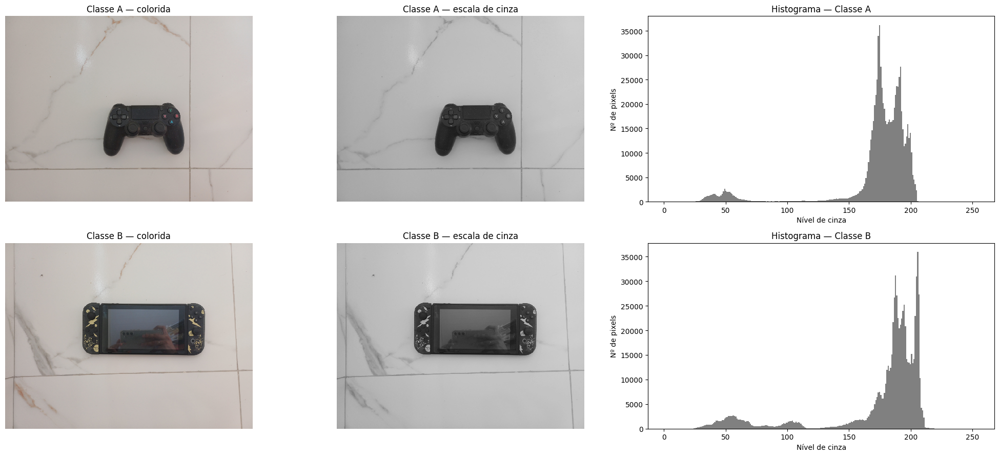

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 9), gridspec_kw={'width_ratios': [1, 1, 1.2]})

for linha, chave in enumerate(imagens):
    axes[linha, 0].imshow(coloridas[chave])
    axes[linha, 0].set_title(f'{chave} — colorida')
    axes[linha, 1].imshow(imagens[chave], cmap='gray', vmin=0, vmax=255)
    axes[linha, 1].set_title(f'{chave} — escala de cinza')
    axes[linha, 0].axis('off')
    axes[linha, 1].axis('off')

    axes[linha, 2].hist(imagens[chave].ravel(), bins=256, range=(0, 255), color='gray')
    axes[linha, 2].set_title(f'Histograma — {chave}')
    axes[linha, 2].set_xlabel('Nível de cinza')
    axes[linha, 2].set_ylabel('Nº de pixels')

plt.tight_layout()
plt.show()

### 2.5 Medições de apoio

Algumas afirmações da interpretação dependem de números que a figura não mostra diretamente. Esta célula os calcula:

- **percentis 1% e 99%** e presença de pixels saturados (0 ou 255);
- **desvio padrão numa região lisa do fundo** (40×40 px, canto superior direito) — como ali não há estrutura, ele estima o ruído já presente na imagem;
- **fração da imagem ocupada pelo objeto** (pixels escuros, < 110);
- **brilho médio do fundo por faixas verticais**, para verificar se a iluminação é uniforme.

In [ ]:
medidas = []
for chave, img in imagens.items():
    faixas = [int(img[:, x:x+128].mean()) for x in range(0, img.shape[1], 128)]
    medidas.append({
        'Classe': chave,
        'Percentil 1%': np.percentile(img, 1),
        'Percentil 99%': np.percentile(img, 99),
        'Pixels em 0 ou 255 (%)': round(100 * np.mean((img == 0) | (img == 255)), 3),
        'Desvio padrão no fundo liso': round(float(img[50:90, 800:840].std()), 2),
        'Área do objeto (%)': round(100 * np.mean(img < 110), 1),
        'Brilho por faixa (esq → dir)': faixas,
    })

pd.DataFrame(medidas).set_index('Classe').T

Classe,Classe A,Classe B
Percentil 1%,37.0,39.0
Percentil 99%,203.0,209.0
Pixels em 0 ou 255 (%),0.0,0.0
Desvio padrão no fundo liso,0.77,0.66
Área do objeto (%),6.5,12.5
Brilho por faixa (esq → dir),"[169, 175, 179, 154, 156, 160, 190, 196]","[173, 182, 173, 158, 161, 160, 183, 200]"


### 2.6 Interpretação

* **Observação visual:** ambas as imagens seguem o mesmo protocolo — objeto escuro e centralizado sobre piso de cerâmica claro, com veios de mármore finos e rejuntes retos entre as placas. A Classe A (controle) tem detalhes de baixo contraste (escuro sobre escuro: direcional, botões, grade do alto-falante), além de um reflexo especular no alto da imagem. A Classe B (Switch) tem elementos de alto contraste (estampas brancas nos Joy-Cons) e reflexos na tela, que mostra o celular e a mão de quem fotografou.

* **Histograma e estatísticas:** perfil bimodal evidente — fundo claro (~150–210) e objeto (~30–60). A Classe B tem ainda um terceiro grupo em torno de 100, correspondente à tela. O desvio padrão global maior da Classe B (44,1 contra 34,7) decorre da maior área ocupada pelo objeto (12,5% contra 6,5%) e desses tons intermediários, e não de ruído. O fundo se divide em vários picos porque a iluminação não é uniforme: as médias por faixa mostram o lado direito mais claro. Nenhum pixel está em 0 ou 255 (0,0% saturados).

* **Limpeza da imagem de trabalho:** as fotos foram capturadas com ISO baixo (100 e 125), o que já limita o ruído do sensor. Além disso, no redimensionamento com `INTER_AREA`, cada pixel novo é a média de cerca de 61 pixels originais (7,8 × 7,8), uma suavização forte. O desvio padrão de ~0,7 no fundo liso confirma que o ruído de captura foi reduzido a um nível desprezível: a imagem de trabalho é uma linha de base adequada, e toda granulação que surgir nas próximas etapas pode ser atribuída ao ruído artificial.

## 3. Inserção de ruído

Nesta seção, cada imagem recebe duas degradações artificiais: ruído gaussiano (3.1) e ruído sal e pimenta (3.2). Usar ruído **artificial**, em vez de fotografar em más condições, tem uma vantagem experimental: os parâmetros são conhecidos e controlados, e a imagem original sem ruído continua disponível como referência. Assim, é possível medir exatamente quanto cada ruído degradou a imagem e, na Seção 4, quanto cada filtro recuperou.

### 3.1 Ruído gaussiano

#### 3.1.1 Conceito

O ruído gaussiano modela as flutuações aleatórias que surgem na captura: agitação térmica dos elétrons no sensor, ruído do circuito de leitura e, principalmente, a amplificação do sinal quando o ISO é alto. Ele é **aditivo**: cada pixel recebe um valor sorteado de uma distribuição normal, somado à sua intensidade original.

$$g(x,y) = f(x,y) + n(x,y), \qquad n(x,y) \sim \mathcal{N}(\mu,\ \sigma^2)$$

em que $f$ é a imagem original, $n$ é o ruído e $g$ é a imagem ruidosa. O sorteio é **independente para cada pixel** e não depende do conteúdo da imagem.

- **Média ($\mu$):** o deslocamento médio. Com $\mu = 0$, o ruído clareia alguns pixels e escurece outros na mesma proporção, sem alterar o brilho geral. Um $\mu \neq 0$ somaria uma mudança de brilho constante, que não é ruído no sentido usual.
- **Desvio padrão ($\sigma$):** a intensidade do ruído. Numa distribuição normal, cerca de 68% das amostras ficam em $\pm\sigma$ e 95% em $\pm 2\sigma$. Com $\sigma = 25$, a maioria dos pixels varia até ±25 níveis, e cerca de 5% variam mais de ±50.

**Clipping.** A imagem só aceita valores entre 0 e 255. Quando a soma ultrapassa esses limites, o valor é cortado. Isso deixa de ser uma simples soma perto dos extremos, e por isso a porcentagem de pixels cortados é registrada.

**Parâmetros escolhidos:** $\mu = 0$ e $\sigma = 25$ (cerca de 10% da faixa 0–255). É um nível em que o ruído é claramente visível, mas a cena continua reconhecível, o que permite observar tanto a degradação quanto a recuperação pelos filtros nas seções seguintes.

**Implementação.** Existem três formas usuais: `np.random.Generator.normal` (NumPy), `cv2.randn` (OpenCV) e `skimage.util.random_noise`. Esta última trabalha na escala 0–1 e recebe a *variância*, e não o desvio padrão ($\sigma = 25$ equivale a `var = (25/255)² ≈ 0,0096`), o que dificulta a leitura dos parâmetros. Foi usado o NumPy, porque a soma, o corte e a conversão ficam explícitos no código, e a semente garante reprodutibilidade.

#### 3.1.2 Implementação

Funções auxiliares usadas nesta e nas próximas seções:

- `ruido_gaussiano`: aplica o ruído e informa a fração de pixels cortados;
- `recorte`: extrai uma região da imagem para exibição ampliada;
- `psnr`: *Peak Signal-to-Noise Ratio*, em dB. Mede o erro médio em relação à original; quanto maior, mais próxima da original.

Duas regiões de 120×120 px são acompanhadas em cada imagem: uma **região lisa do fundo**, sem veios nem rejuntes, onde toda variação é ruído, e uma **região de detalhe** do objeto (botões do controle e Joy-Con esquerdo do Switch).

In [ ]:
def ruido_gaussiano(img, media, sigma, semente=SEMENTE):
    # Soma ruído N(media, sigma²) a cada pixel e corta o resultado em [0, 255].
    # Retorna a imagem ruidosa (uint8) e a fração de pixels que precisaram ser cortados.
    rng = np.random.default_rng(semente)
    soma = img.astype(np.float64) + rng.normal(media, sigma, img.shape)
    frac_cortada = np.mean((soma < 0) | (soma > 255))
    return np.clip(soma, 0, 255).round().astype(np.uint8), frac_cortada

def recorte(img, regiao):
    y0, y1, x0, x1 = regiao
    return img[y0:y1, x0:x1]

def psnr(original, degradada):
    mse = np.mean((original.astype(np.float64) - degradada.astype(np.float64)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

# regiões (linha_ini, linha_fim, coluna_ini, coluna_fim) na imagem 1024x768
REGIOES = {
    'Classe A': {'fundo': (60, 180, 790, 910), 'detalhe': (360, 480, 600, 720)},
    'Classe B': {'fundo': (60, 180, 790, 910), 'detalhe': (250, 370, 315, 435)},
}

In [ ]:
MEDIA = 0
SIGMA_PRINCIPAL = 25
SIGMAS = [SIGMA_PRINCIPAL]

ruido_g = {}   # ruido_g[(classe, sigma)] -> imagem ruidosa
linhas = []

for chave, img in imagens.items():
    fundo = img >= 120    # máscara do fundo (pixels claros da original)
    objeto = img < 110    # máscara do objeto (pixels escuros da original)

    for sigma in SIGMAS:
        ruidosa, cortados = ruido_gaussiano(img, MEDIA, sigma)
        ruido_g[(chave, sigma)] = ruidosa
        efetivo = ruidosa.astype(np.float64) - img   # ruído que de fato ficou na imagem

        linhas.append({
            'Classe': chave, 'μ': MEDIA, 'σ': sigma,
            'Pixels cortados (%)': round(100 * cortados, 2),
            'PSNR (dB)': round(psnr(img, ruidosa), 2),
            'Desvio no fundo liso': round(float(recorte(ruidosa, REGIOES[chave]['fundo']).std()), 2),
            'Média fundo: antes → depois': f'{img[fundo].mean():.1f} → {ruidosa[fundo].mean():.1f}',
            'Média objeto: antes → depois': f'{img[objeto].mean():.1f} → {ruidosa[objeto].mean():.1f}',
            'Desvio do ruído efetivo (fundo | objeto)': f'{efetivo[fundo].std():.1f} | {efetivo[objeto].std():.1f}',
        })

tabela_gauss = pd.DataFrame(linhas).set_index(['Classe', 'σ'])
tabela_gauss

,,μ,Pixels cortados (%),PSNR (dB),Desvio no fundo liso,Média fundo: antes → depois,Média objeto: antes → depois,Desvio do ruído efetivo (fundo | objeto)
Classe,σ,,,,,,,
Classe A,25,0,0.57,20.21,24.83,181.4 → 181.4,50.4 → 50.9,24.9 | 24.2
Classe B,25,0,1.09,20.25,24.44,190.4 → 190.3,65.7 → 65.9,24.8 | 24.6


In [ ]:
# Contraste aproximado dos detalhes internos de cada objeto (na imagem original).
# Limiares escolhidos a partir do histograma da região de detalhe:
#   corpo do objeto < 80 | letras do controle entre 80 e 130 | estampas do Switch > 150
det_A = recorte(imagens['Classe A'], REGIOES['Classe A']['detalhe'])
det_B = recorte(imagens['Classe B'], REGIOES['Classe B']['detalhe'])

contraste = pd.DataFrame({
    'Detalhe': ['Letras dos botões (controle)', 'Estampas brancas (Switch)'],
    'Nível do corpo': [np.median(det_A[det_A < 80]), np.median(det_B[det_B < 80])],
    'Nível do detalhe': [np.median(det_A[(det_A >= 80) & (det_A < 130)]), np.median(det_B[det_B > 150])],
})
contraste['Contraste Δ'] = contraste['Nível do detalhe'] - contraste['Nível do corpo']
contraste[f'Δ / σ (σ={SIGMA_PRINCIPAL})'] = (contraste['Contraste Δ'] / SIGMA_PRINCIPAL).round(1)
contraste

,Detalhe,Nível do corpo,Nível do detalhe,Contraste Δ,Δ / σ (σ=25)
0,Letras dos botões (controle),53.0,102.5,49.5,2.0
1,Estampas brancas (Switch),54.0,174.0,120.0,4.8


#### 3.1.3 Visualização

Três figuras:

1. **Imagem inteira**, original × ruidosa (σ = 25): efeito global.
2. **Recortes ampliados** das regiões de fundo e de detalhe, original × ruidosa. Na imagem inteira reduzida para a tela, a granulação fica atenuada; no recorte, cada pixel da imagem aparece como um bloco.
3. **Mapa do ruído efetivo** (ruidosa − original) na região do objeto, com os histogramas antes e depois. O mapa mostra se o ruído depende do conteúdo: se dependesse, a silhueta do objeto apareceria nele. No mapa, cinza médio = sem alteração, claro = pixel clareado, escuro = pixel escurecido.

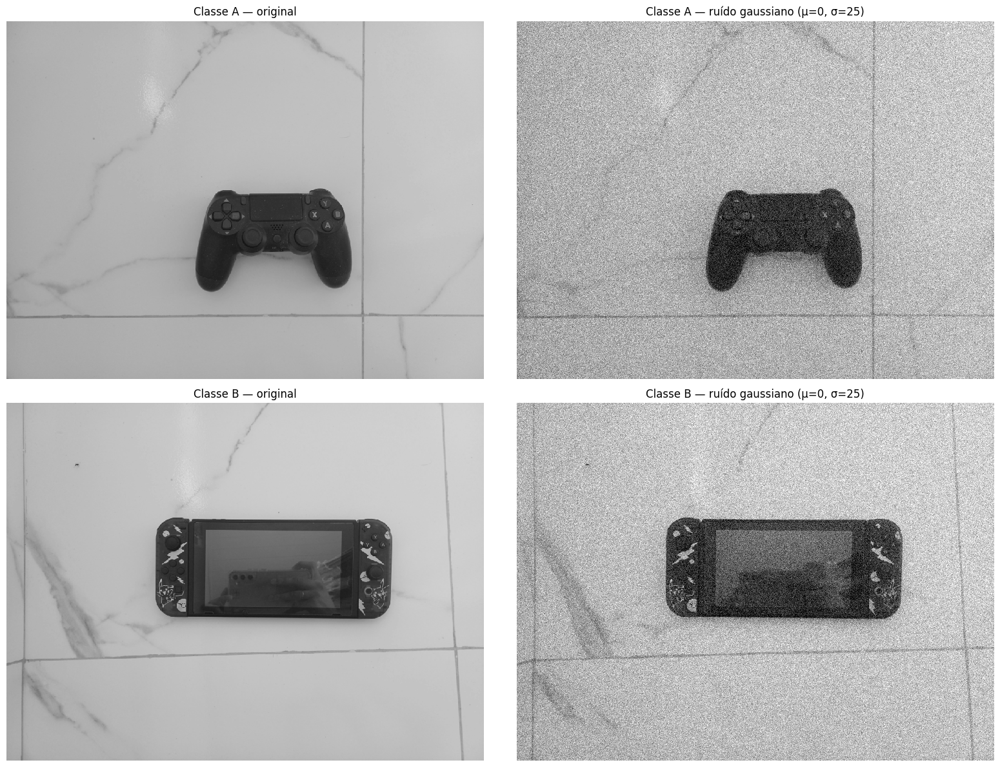

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for linha, chave in enumerate(imagens):
    axes[linha, 0].imshow(imagens[chave], cmap='gray', vmin=0, vmax=255)
    axes[linha, 0].set_title(f'{chave} — original')
    axes[linha, 1].imshow(ruido_g[(chave, SIGMA_PRINCIPAL)], cmap='gray', vmin=0, vmax=255)
    axes[linha, 1].set_title(f'{chave} — ruído gaussiano (μ={MEDIA}, σ={SIGMA_PRINCIPAL})')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

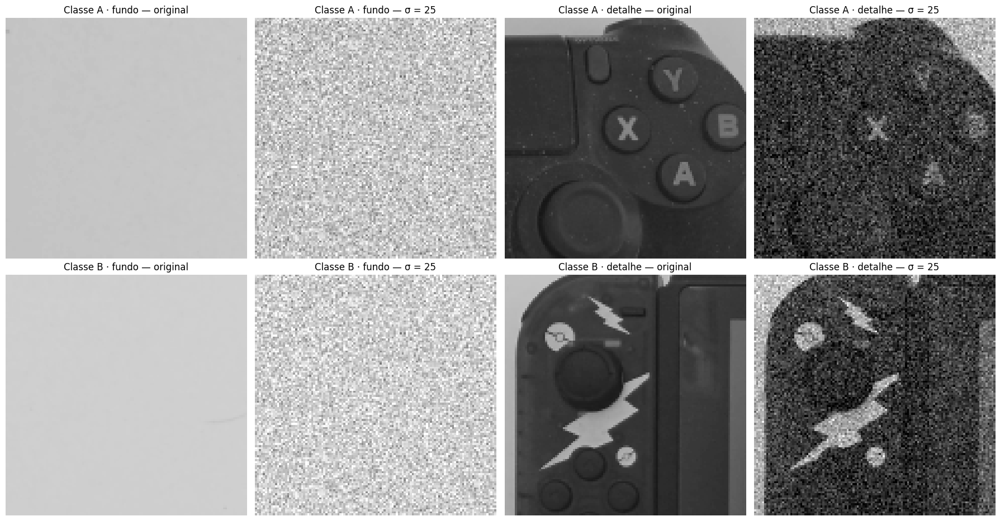

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for linha, chave in enumerate(imagens):
    paineis = [('fundo', 'original', imagens[chave]), ('fundo', f'σ = {SIGMA_PRINCIPAL}', ruido_g[(chave, SIGMA_PRINCIPAL)]),
               ('detalhe', 'original', imagens[chave]), ('detalhe', f'σ = {SIGMA_PRINCIPAL}', ruido_g[(chave, SIGMA_PRINCIPAL)])]
    for col, (nome_regiao, rotulo, img) in enumerate(paineis):
        axes[linha, col].imshow(recorte(img, REGIOES[chave][nome_regiao]), cmap='gray', vmin=0, vmax=255)
        axes[linha, col].set_title(f'{chave} · {nome_regiao} — {rotulo}')
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

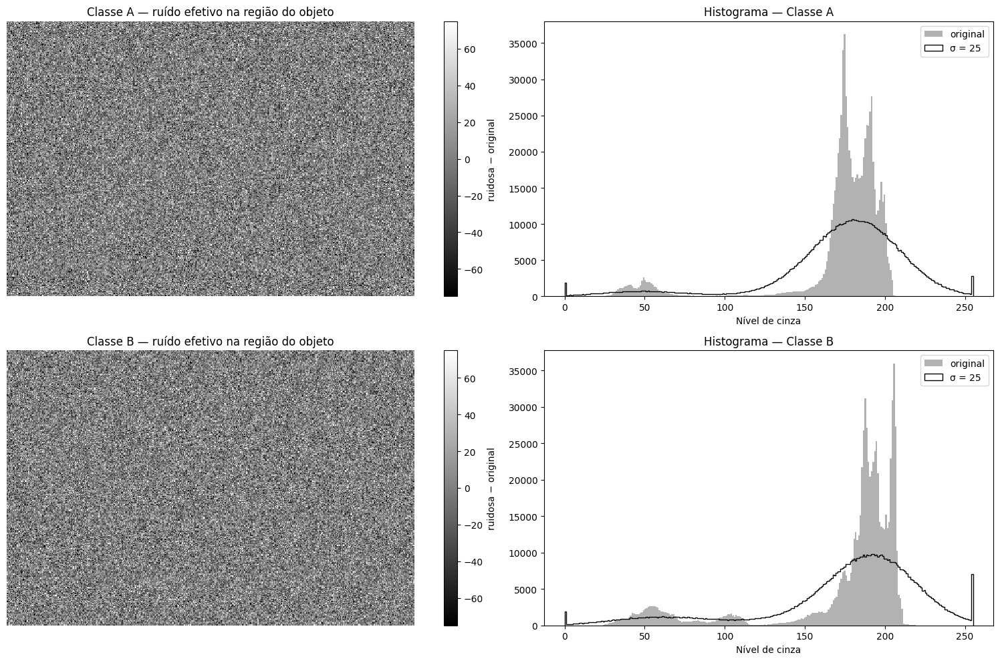

In [ ]:
REGIAO_MAPA = {'Classe A': (330, 600, 350, 750), 'Classe B': (220, 490, 290, 690)}

fig, axes = plt.subplots(2, 2, figsize=(17, 10), gridspec_kw={'width_ratios': [1.3, 1]})
for linha, chave in enumerate(imagens):
    efetivo = ruido_g[(chave, SIGMA_PRINCIPAL)].astype(np.float64) - imagens[chave]
    mapa = axes[linha, 0].imshow(recorte(efetivo, REGIAO_MAPA[chave]), cmap='gray', vmin=-75, vmax=75)
    plt.colorbar(mapa, ax=axes[linha, 0], fraction=0.03, label='ruidosa − original')
    axes[linha, 0].set_title(f'{chave} — ruído efetivo na região do objeto')
    axes[linha, 0].axis('off')

    axes[linha, 1].hist(imagens[chave].ravel(), bins=256, range=(0, 255), color='gray', alpha=0.6, label='original')
    axes[linha, 1].hist(ruido_g[(chave, SIGMA_PRINCIPAL)].ravel(), bins=256, range=(0, 255),
                        histtype='step', color='black', label=f'σ = {SIGMA_PRINCIPAL}')
    axes[linha, 1].set_title(f'Histograma — {chave}')
    axes[linha, 1].set_xlabel('Nível de cinza')
    axes[linha, 1].legend()
plt.tight_layout()
plt.show()

#### 3.1.4 Impacto em algoritmos de Visão Computacional

Para verificar o efeito do ruído em algoritmos reais, e não só no aspecto visual, dois algoritmos clássicos são aplicados antes e depois do ruído (σ = 25):

- **Canny** (limiares 50 e 150): detector de bordas baseado no gradiente, etapa comum antes de medir, contar ou reconhecer contornos;
- **Otsu**: limiarização automática que separa objeto e fundo pelo histograma, uma forma simples de segmentação.

Os parâmetros são os mesmos nas duas condições; só a imagem muda. Os mesmos testes serão repetidos após a filtragem, na Seção 4, para medir o quanto cada filtro recupera.

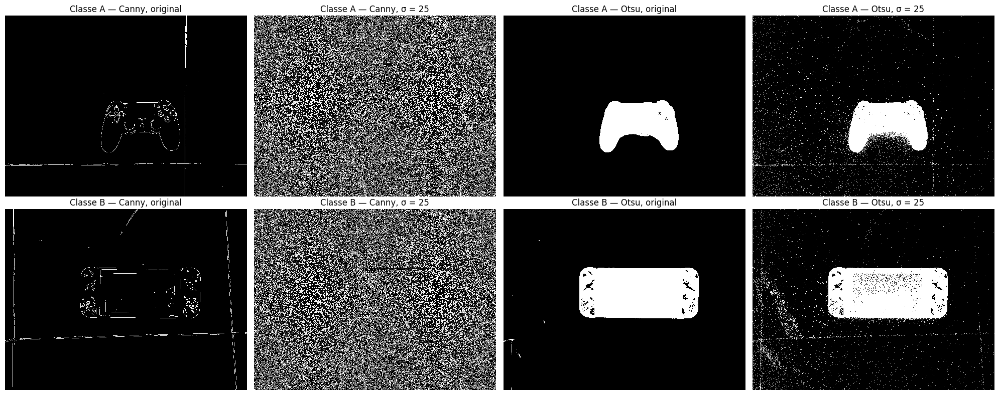

Pixels de borda — Canny (%)  Limiar de Otsu  \
Classe   Versão                                                  
Classe A original                         0.88             116   
         σ = 25                          36.25             124   
Classe B original                         1.39             129   
         σ = 25                          36.27             132   

                   Regiões segmentadas — Otsu  
Classe   Versão                                
Classe A original                           4  
         σ = 25                         11370  
Classe B original                          39  
         σ = 25                          9950

In [ ]:
def avaliar_algoritmos(img):
    bordas = cv2.Canny(img, 50, 150)
    limiar, mascara = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    n_regioes = cv2.connectedComponents(mascara)[0] - 1   # desconta o fundo
    return bordas, mascara, {
        'Pixels de borda — Canny (%)': round(100 * np.mean(bordas > 0), 2),
        'Limiar de Otsu': int(limiar),
        'Regiões segmentadas — Otsu': n_regioes,
    }

resultados_vc = []
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for linha, chave in enumerate(imagens):
    versoes = [('original', imagens[chave]), (f'σ = {SIGMA_PRINCIPAL}', ruido_g[(chave, SIGMA_PRINCIPAL)])]
    for j, (rotulo, img) in enumerate(versoes):
        bordas, mascara, medidas = avaliar_algoritmos(img)
        resultados_vc.append({'Classe': chave, 'Versão': rotulo, **medidas})
        axes[linha, j].imshow(bordas, cmap='gray')
        axes[linha, j].set_title(f'{chave} — Canny, {rotulo}')
        axes[linha, j + 2].imshow(mascara, cmap='gray')
        axes[linha, j + 2].set_title(f'{chave} — Otsu, {rotulo}')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

pd.DataFrame(resultados_vc).set_index(['Classe', 'Versão'])

#### 3.1.5 Interpretação

**Parâmetros registrados:** média μ = 0 e desvio padrão σ = 25. Apenas 0,57% (A) e 1,09% (B) dos pixels sofreram clipping.

**Impacto visual observado:** o ruído deixa a imagem inteira granulada (PSNR de ~20 dB nas duas classes). Nos recortes, as letras dos botões do controle ficam quase ilegíveis (Y e B praticamente desaparecem), assim como os veios mais finos do mármore, enquanto as estampas do Switch, os rejuntes e o contorno dos objetos continuam nítidos. O que decide se um detalhe sobrevive é o seu contraste em relação a σ: as letras têm Δ ≈ 50 (Δ/σ ≈ 2), e as estampas, Δ ≈ 120 (Δ/σ ≈ 4,8). Por isso a Classe A perde seus detalhes internos antes da Classe B, embora o PSNR seja quase idêntico nas duas (20,21 × 20,25 dB): a métrica mede a energia do ruído, não quais detalhes foram perdidos.

**1. O ruído está distribuído uniformemente na imagem?**

* **Espacialmente: sim.** O ruído é independente do conteúdo e homocedástico (mesma variância em toda a imagem). O mapa de ruído efetivo não mostra a silhueta dos objetos, e o desvio padrão do ruído é praticamente igual no fundo e no objeto (A: 24,9 × 24,2; B: 24,8 × 24,6).
* **Em amplitude: não.** As alterações seguem uma distribuição normal: variações pequenas são frequentes e as grandes, raras (~95% ficam dentro de ±2σ). Nos extremos da escala (0 e 255), a distribuição é truncada pelo clipping. Com σ = 25, esse corte atinge só ~1% dos pixels, e as médias quase não mudam (objeto da Classe A: 50,4 → 50,9).
* **Na percepção visual: não.** Embora estatisticamente uniforme, o ruído é mais perceptível no piso liso, onde qualquer variação é ruído, e nos detalhes de baixo contraste. Estruturas grandes, como o reflexo especular e a diferença de iluminação entre os lados, resistem, porque sua informação está nas baixas frequências, enquanto o ruído se espalha igualmente por todas.

**2. Que tipo de problema esse ruído pode causar para algoritmos de Visão Computacional?**

* **Detecção de bordas (Canny):** as variações aleatórias entre pixels vizinhos criam gradientes artificiais. Os pixels marcados como borda saltam de 0,88% para 36,25% na Classe A e de 1,39% para 36,27% na Classe B: cerca de 285 mil falsos pixels de borda encobrem o contorno real dos objetos.
* **Segmentação (Otsu):** o limiar global quase não muda (116 → 124 em A; 129 → 132 em B), mas o ruído destrói a coerência espacial da máscara. As regiões segmentadas passam de 4 para 11.370 (A) e de 39 para 9.950 (B). Os erros se concentram onde a intensidade original está perto do limiar, como a tela do Switch (~100), que ficou esburacada.

### 3.2 Ruído sal e pimenta

#### 3.2.1 Conceito

O ruído sal e pimenta é um **ruído impulsivo**: em vez de perturbar levemente todos os pixels, ele **substitui** o valor de uma fração dos pixels por um dos extremos da escala — 255 (branco, o "sal") ou 0 (preto, a "pimenta"). O nome vem da aparência: pontos brancos e pretos espalhados, como grãos de sal e pimenta sobre a imagem.

$$g(x,y) = \begin{cases} 255 & \text{com probabilidade } p/2 \ \text{(sal)} \\ 0 & \text{com probabilidade } p/2 \ \text{(pimenta)} \\ f(x,y) & \text{com probabilidade } 1-p \ \text{(pixel intacto)} \end{cases}$$

Diferenças conceituais em relação ao ruído gaussiano:

| | Gaussiano | Sal e pimenta |
|---|---|---|
| Operação | **Soma** um valor aleatório | **Substitui** o valor original |
| Pixels afetados | Praticamente todos | Apenas a fração *p* |
| Tamanho da alteração | Pequeno na maioria dos pixels (~±σ) | Máximo: o pixel vai a 0 ou 255 |
| Depende do valor original? | O resultado sim (f + n) | Não: o novo valor ignora o original |
| Pixels restantes | Todos perturbados | Exatamente iguais aos originais |

**Parâmetros escolhidos:** densidade *p* = 5% dos pixels, com proporção de 50% de sal e 50% de pimenta. É um nível em que os impulsos são claramente visíveis sem encobrir a cena, comparável ao ruído gaussiano com σ = 25.

**Implementação.** Existem duas formas de sortear os pixels:

- **Sorteio independente por pixel** (cada pixel é alterado se um número aleatório for menor que *p*): é o que faz `skimage.util.random_noise(mode='s&p')`. A quantidade de pixels alterados varia em torno de *p* a cada execução.
- **Sorteio de uma quantidade exata** de posições sem reposição (`rng.choice(..., replace=False)`): exatamente *p* × N pixels são sorteados.

Foi usada a segunda, porque a atividade pede para **registrar a porcentagem de pixels alterados**, e ela garante que a porcentagem sorteada seja exata. O PDF menciona uma função pronta no notebook base; aqui foi escrita uma implementação própria para medir separadamente duas grandezas: a porcentagem **sorteada** e a porcentagem **efetivamente alterada**. Elas só diferem quando o pixel sorteado já estava no extremo (por exemplo, "sal" sobre um pixel que já valia 255). Como a Seção 2.5 mostrou que essas imagens não têm pixels em 0 ou 255, espera-se que as duas coincidam.

#### 3.2.2 Implementação

Além do PSNR, é calculado o **MAE** (*Mean Absolute Error*, erro absoluto médio), a diferença média em níveis de cinza entre a imagem ruidosa e a original. As duas métricas tratam os erros de modo diferente: o PSNR vem do erro **quadrático** e penaliza muito os erros grandes; o MAE pesa todos os erros de forma proporcional. Essa diferença será importante na comparação entre os dois ruídos (Seção 6).

In [ ]:
def sal_pimenta(img, densidade, proporcao_sal=0.5, semente=SEMENTE):
    # Substitui exatamente round(densidade × N) pixels, sorteados sem reposição:
    # uma parte por 255 (sal) e o restante por 0 (pimenta).
    # Retorna a imagem ruidosa e o número de pixels sorteados.
    rng = np.random.default_rng(semente)
    ruidosa = img.copy()
    plano = ruidosa.ravel()                      # visão 1D da mesma memória
    n_sorteados = int(round(densidade * img.size))
    posicoes = rng.choice(img.size, n_sorteados, replace=False)
    n_sal = int(round(n_sorteados * proporcao_sal))
    plano[posicoes[:n_sal]] = 255
    plano[posicoes[n_sal:]] = 0
    return ruidosa, n_sorteados

def mae(original, degradada):
    return np.mean(np.abs(original.astype(np.float64) - degradada.astype(np.float64)))

In [ ]:
DENSIDADE_PRINCIPAL = 0.05
DENSIDADES = [DENSIDADE_PRINCIPAL]

ruido_sp = {}   # ruido_sp[(classe, densidade)] -> imagem ruidosa
linhas = []

for chave, img in imagens.items():
    for dens in DENSIDADES:
        ruidosa, n = sal_pimenta(img, dens)
        ruido_sp[(chave, dens)] = ruidosa
        linhas.append({
            'Classe': chave, 'Densidade': f'{dens:.0%}',
            'Pixels sorteados (%)': round(100 * n / img.size, 3),
            'Pixels efetivamente alterados (%)': round(100 * np.mean(ruidosa != img), 3),
            'PSNR (dB)': round(psnr(img, ruidosa), 2),
            'MAE': round(mae(img, ruidosa), 2),
        })

tabela_sp = pd.DataFrame(linhas).set_index(['Classe', 'Densidade'])
tabela_sp

,,Pixels sorteados (%),Pixels efetivamente alterados (%),PSNR (dB),MAE
Classe,Densidade,,,,
Classe A,5%,5.0,5.0,18.23,6.39
Classe B,5%,5.0,5.0,18.04,6.38


#### 3.2.3 Visualização

1. **Imagem inteira**: original × gaussiano (σ = 25) × sal e pimenta (5%), lado a lado para comparar os dois ruídos. Na imagem inteira reduzida para a tela, parte dos pontos isolados some na redução; os recortes a seguir mostram a densidade real.
2. **Recortes ampliados** das regiões de fundo e de detalhe: original, gaussiano (σ = 25) e sal e pimenta (5%).

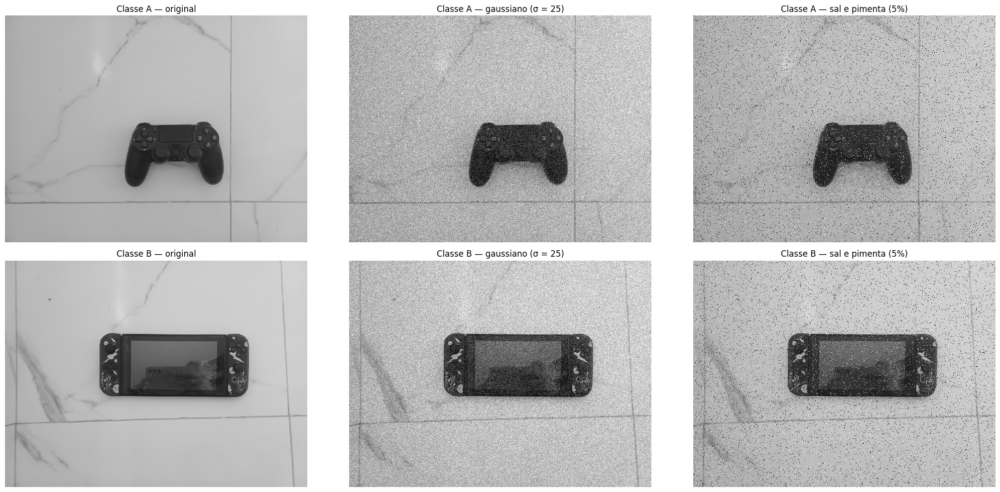

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(21, 10))
for linha, chave in enumerate(imagens):
    versoes = [('original', imagens[chave]),
               (f'gaussiano (σ = {SIGMA_PRINCIPAL})', ruido_g[(chave, SIGMA_PRINCIPAL)]),
               (f'sal e pimenta ({DENSIDADE_PRINCIPAL:.0%})', ruido_sp[(chave, DENSIDADE_PRINCIPAL)])]
    for col, (rotulo, img) in enumerate(versoes):
        axes[linha, col].imshow(img, cmap='gray', vmin=0, vmax=255)
        axes[linha, col].set_title(f'{chave} — {rotulo}')
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

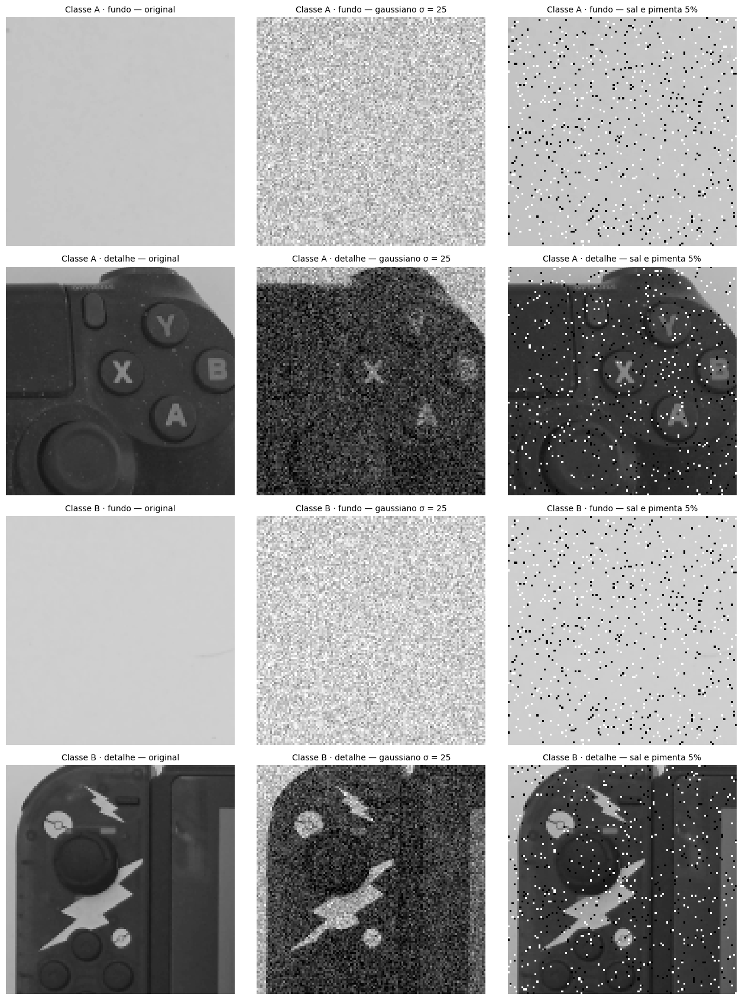

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(13, 17))
for i, chave in enumerate(imagens):
    for j, nome_regiao in enumerate(['fundo', 'detalhe']):
        lin = 2 * i + j
        regiao = REGIOES[chave][nome_regiao]
        versoes = [('original', imagens[chave]),
                   (f'gaussiano σ = {SIGMA_PRINCIPAL}', ruido_g[(chave, SIGMA_PRINCIPAL)]),
                   (f'sal e pimenta {DENSIDADE_PRINCIPAL:.0%}', ruido_sp[(chave, DENSIDADE_PRINCIPAL)])]
        for col, (rotulo, img) in enumerate(versoes):
            axes[lin, col].imshow(recorte(img, regiao), cmap='gray', vmin=0, vmax=255)
            axes[lin, col].set_title(f'{chave} · {nome_regiao} — {rotulo}', fontsize=10)
            axes[lin, col].axis('off')
plt.tight_layout()
plt.show()

#### 3.2.4 Comparação com o ruído gaussiano e impacto em algoritmos

Os dois ruídos são comparados pelas métricas de erro e pelos mesmos testes de Canny e Otsu da Seção 3.1. Esses números sustentam a resposta a "qual ruído degradou mais?", na Seção 6.

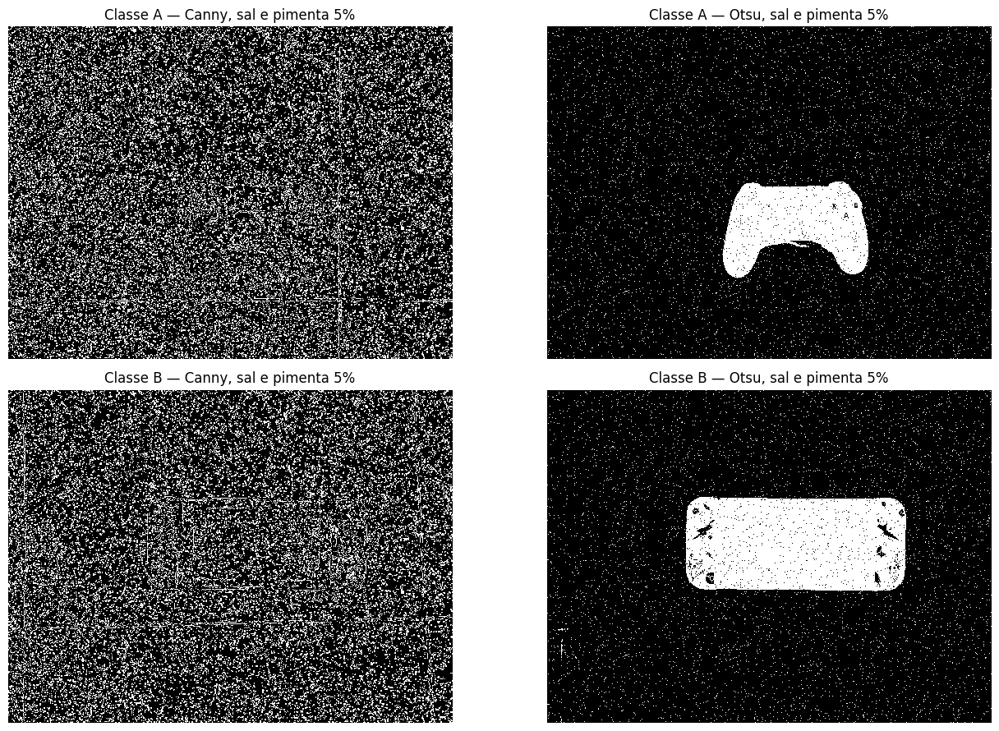

Pixels alterados (%)    MAE  PSNR (dB)  \
Classe   Ruído                                                      
Classe A Gaussiano σ = 25                 98.39  19.89      20.21   
         Sal e pimenta 5%                  5.00   6.39      18.23   
Classe B Gaussiano σ = 25                 98.39  19.84      20.25   
         Sal e pimenta 5%                  5.00   6.38      18.04   

                           Pixels de borda — Canny (%)  Limiar de Otsu  \
Classe   Ruído                                                           
Classe A Gaussiano σ = 25                        36.25             124   
         Sal e pimenta 5%                        24.25             109   
Classe B Gaussiano σ = 25                        36.27             132   
         Sal e pimenta 5%                        23.67             124   

                           Regiões segmentadas — Otsu  
Classe   Ruído                                         
Classe A Gaussiano σ = 25                       11370  
         Sal e pimenta 5%                       16572  
Classe B Gaussiano σ = 25                        9950  
         Sal e pimenta 5%                       15387

In [ ]:
linhas = []
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for linha, chave in enumerate(imagens):
    img = imagens[chave]
    for rotulo, ruidosa in [(f'Gaussiano σ = {SIGMA_PRINCIPAL}', ruido_g[(chave, SIGMA_PRINCIPAL)]),
                            (f'Sal e pimenta {DENSIDADE_PRINCIPAL:.0%}', ruido_sp[(chave, DENSIDADE_PRINCIPAL)])]:
        _, _, medidas = avaliar_algoritmos(ruidosa)
        linhas.append({'Classe': chave, 'Ruído': rotulo,
                       'Pixels alterados (%)': round(100 * np.mean(ruidosa != img), 2),
                       'MAE': round(mae(img, ruidosa), 2),
                       'PSNR (dB)': round(psnr(img, ruidosa), 2), **medidas})

    bordas, mascara, _ = avaliar_algoritmos(ruido_sp[(chave, DENSIDADE_PRINCIPAL)])
    axes[linha, 0].imshow(bordas, cmap='gray')
    axes[linha, 0].set_title(f'{chave} — Canny, sal e pimenta {DENSIDADE_PRINCIPAL:.0%}')
    axes[linha, 1].imshow(mascara, cmap='gray')
    axes[linha, 1].set_title(f'{chave} — Otsu, sal e pimenta {DENSIDADE_PRINCIPAL:.0%}')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

pd.DataFrame(linhas).set_index(['Classe', 'Ruído'])

#### 3.2.5 Interpretação

**Parâmetros registrados:** densidade de 5% (50% sal e 50% pimenta). A porcentagem de pixels efetivamente alterados foi idêntica à sorteada nas duas classes (5,000%): como nenhum pixel original estava em 0 ou 255 (Seção 2.5), todo impulso alterou o pixel atingido.

**1. Como esse ruído se diferencia visualmente do gaussiano?**

* **Padrão de corrupção:** o gaussiano modifica 98,39% dos pixels com variações contínuas e moderadas, gerando uma granulação fina em toda a imagem. O sal e pimenta corrompe exatamente 5% dos pixels, levando cada um a um extremo da escala, e mantém os outros 95% idênticos à original. Visualmente, aparece como pontos pretos e brancos isolados, sem tons intermediários.
* **Preservação de feições finas:** como 95% dos pixels permanecem intactos, a estrutura da cena continua visível entre os impulsos. As letras Y, B, A e X dos botões do controle e as estampas dos Joy-Cons continuam identificáveis; com o gaussiano, as feições de baixo contraste são encobertas pela granulação.
* **Visibilidade depende da região:** como a pimenta leva o pixel a 0 e o sal a 255, a alteração é Δ = valor original (pimenta) ou Δ = 255 − valor original (sal). No piso claro (~181 na Classe A), a pimenta muda o pixel em ~181 níveis e se destaca como ponto preto, enquanto o sal muda só ~74 e quase se confunde com o fundo. No objeto escuro (~50), acontece o inverso: os pontos brancos se destacam. Nas estampas claras do Switch, a pimenta abre buracos pretos.

**2. Em quais situações esse ruído aparece em sistemas reais de captura de imagem?**

Sempre que um pixel perde a informação da cena e assume um valor extremo:
* **falhas pontuais no sensor:** *dead pixels* (travados no preto) e *hot pixels* (travados no branco, mais frequentes com o envelhecimento do sensor, em temperaturas elevadas e em exposições longas);
* **erros de inversão de bits** (*bit flips*) na transmissão de vídeo digital por canais ruidosos (câmeras sem fio, enlaces de rádio, drones);
* **falhas de amostragem no conversor A/D** e **corrupção de memória ou armazenamento**.

## 4. Filtragem passa-baixa gaussiana no domínio da frequência

### 4.1 Conceito

**Domínio da frequência.** Toda imagem pode ser descrita como uma soma de padrões ondulatórios (senos e cossenos) de diferentes frequências, orientações e intensidades. A **Transformada de Fourier 2D** (calculada pela FFT) faz essa decomposição e mostra *quanto* de cada frequência existe na imagem:

- **baixas frequências** = variações lentas de intensidade: regiões homogêneas, gradientes de iluminação, a forma geral dos objetos;
- **altas frequências** = variações rápidas entre pixels vizinhos: bordas, contornos finos, texturas **e ruído**.

O **espectro de magnitude** exibe essa decomposição como imagem: depois do `fftshift`, o centro corresponde à frequência zero (o brilho médio), e quanto mais longe do centro, maior a frequência. Como os valores variam muitas ordens de grandeza, o espectro é exibido em escala logarítmica, `log(1 + |F|)`.

**Filtro passa-baixa.** Multiplica o espectro por uma máscara $H(u,v)$ que vale ~1 no centro e decai para 0 nas altas frequências, e depois volta ao domínio do espaço pela transformada inversa:

$$g = \mathcal{F}^{-1}\{\,H \cdot \mathcal{F}\{f\}\,\}$$

- **Por que reduz o ruído:** o ruído gaussiano é independente de pixel para pixel, então sua energia se espalha igualmente por *todas* as frequências (ruído branco). A cena, por outro lado, concentra a maior parte da energia nas baixas frequências. Cortar as altas frequências remove uma grande parte do ruído e uma pequena parte da cena.
- **Por que também remove detalhes:** bordas e contornos finos também são altas frequências. O filtro não distingue "variação rápida causada por ruído" de "variação rápida causada por uma borda real", e atenua as duas.

**Tamanho do kernel × suavização.** No domínio do espaço, o filtro gaussiano é um kernel (máscara) que substitui cada pixel por uma média ponderada da vizinhança. Pelo **teorema da convolução**, convoluir com um kernel no espaço é o mesmo que multiplicar pela sua transformada na frequência. Quanto **maior** o kernel no espaço, **mais estreita** é sua máscara $H$ na frequência: mais frequências são cortadas e maior é a suavização.

**Abordagem adotada.** O PDF pede filtragem no domínio da frequência e sugere kernels 3×3 e 7×7. Para atender às duas coisas com exatidão:

1. o kernel gaussiano k×k é gerado com `cv2.getGaussianKernel` (o mesmo usado pelo `cv2.GaussianBlur`);
2. ele é colocado numa matriz de zeros do tamanho da imagem, com o centro do kernel na posição (0, 0);
3. a FFT dessa matriz é a máscara $H(u,v)$ **exata** desse kernel;
4. a imagem é filtrada por `FFT → multiplicação por H → IFFT`.

A alternativa mais comum seria definir diretamente $H(u,v) = e^{-D^2/2D_0^2}$ com uma frequência de corte $D_0$ escolhida. Ela também é válida, mas exigiria escolher valores de $D_0$ "equivalentes" a 3×3 e 7×7 sem uma correspondência exata. Com a abordagem adotada, a máscara é derivada do próprio kernel, e o resultado pode ser verificado numericamente contra a convolução no espaço (célula de verificação abaixo).

### 4.2 Implementação

- `kernel_gaussiano(k)`: kernel 2D k×k, produto externo do kernel 1D do OpenCV;
- `mascara_do_kernel(k, formato)`: máscara $H(u,v)$ do kernel, calculada pela FFT;
- `filtrar_frequencia(img, H)`: pipeline FFT → multiplicação → IFFT. Retorna a **parte real**: como o kernel é simétrico, $H$ é real e a parte imaginária do resultado é apenas erro numérico (~10⁻¹³). Usar `np.abs` seria incorreto, porque trocaria o sinal de valores negativos em vez de preservá-los;
- `espectro(img)`: espectro de magnitude centralizado, em escala log.

In [ ]:
KERNELS = [3, 7]

def kernel_gaussiano(k):
    g1 = cv2.getGaussianKernel(k, 0)       # sigma=0: o OpenCV define o sigma a partir de k
    return g1 @ g1.T                       # kernel 2D separável

def mascara_do_kernel(k, formato):
    # Máscara H(u,v) exata do kernel k×k para uma imagem de 'formato' (linhas, colunas)
    P = np.zeros(formato)
    P[:k, :k] = kernel_gaussiano(k)
    P = np.roll(P, (-(k // 2), -(k // 2)), axis=(0, 1))   # centro do kernel em (0, 0)
    return np.fft.fft2(P)

def filtrar_frequencia(img, H):
    resultado = np.fft.ifft2(np.fft.fft2(img.astype(np.float64)) * H)
    return resultado.real, np.abs(resultado.imag).max()

def para_uint8(x):
    return np.clip(x, 0, 255).round().astype(np.uint8)

def espectro(img):
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))))

formato = imagens['Classe A'].shape
H = {k: mascara_do_kernel(k, formato) for k in KERNELS}

for k in KERNELS:
    g1 = cv2.getGaussianKernel(k, 0).ravel()
    print(f'Kernel {k}×{k} — pesos 1D: {np.round(g1, 4)}')
    print(f'   parte imaginária máxima de H: {np.abs(H[k].imag).max():.1e}')

Kernel 3×3 — pesos 1D: [0.25 0.5  0.25]
   parte imaginária máxima de H: 1.7e-16
Kernel 7×7 — pesos 1D: [0.0312 0.1094 0.2188 0.2812 0.2188 0.1094 0.0312]
   parte imaginária máxima de H: 1.8e-16


**Verificação.** Se o pipeline na frequência estiver correto, o resultado deve ser idêntico à convolução do mesmo kernel no espaço. Um detalhe: a FFT trata a imagem como **periódica** (a borda direita "encosta" na esquerda), o que equivale a uma convolução com borda circular. Por isso a comparação é feita de duas formas: contra uma convolução com borda circular (deve coincidir em toda a imagem) e contra o `cv2.GaussianBlur` padrão, que espelha a borda (deve coincidir no interior e diferir só nos pixels da margem).

In [ ]:
img_teste = imagens['Classe A'].astype(np.float64)
linhas = []
for k in KERNELS:
    r = k // 2
    freq, resid_imag = filtrar_frequencia(img_teste, H[k])

    # convolução no espaço com borda circular (padding periódico)
    ref_circular = cv2.filter2D(np.pad(img_teste, r, mode='wrap'), -1, kernel_gaussiano(k))[r:-r, r:-r]
    ref_blur = cv2.GaussianBlur(img_teste, (k, k), 0)
    dif_blur = np.abs(freq - ref_blur)

    linhas.append({
        'Kernel': f'{k}×{k}',
        'Máx. |frequência − espaço circular|': f'{np.abs(freq - ref_circular).max():.1e}',
        'Máx. |frequência − GaussianBlur| no interior': f'{dif_blur[r+1:-r-1, r+1:-r-1].max():.1e}',
        'Máx. |frequência − GaussianBlur| na margem': round(dif_blur.max(), 1),
        'Parte imaginária residual': f'{resid_imag:.1e}',
    })
pd.DataFrame(linhas).set_index('Kernel')

,Máx. |frequência − espaço circular|,Máx. |frequência − GaussianBlur| no interior,Máx. |frequência − GaussianBlur| na margem,Parte imaginária residual
Kernel,,,,
3×3,8.5e-14,8.5e-14,18.1,5.9e-14
7×7,8.5e-14,8.5e-14,24.7,6.5e-14


### 4.3 Espectros e máscaras

Duas figuras, para ver o que acontece no domínio da frequência antes de olhar o resultado no espaço:

1. **Espectros de magnitude**: original, com ruído gaussiano, com sal e pimenta, e o ruído gaussiano depois do filtro 7×7. Quanto mais claro, mais energia naquela frequência (a barra indica o valor de log(1 + |F|));
2. **Máscaras $H(u,v)$** dos dois kernels (claro = ganho alto) e o perfil de cada uma ao longo da linha central. A linha pontilhada marca o ganho 0,5: a frequência em que o filtro já reduz a amplitude pela metade.

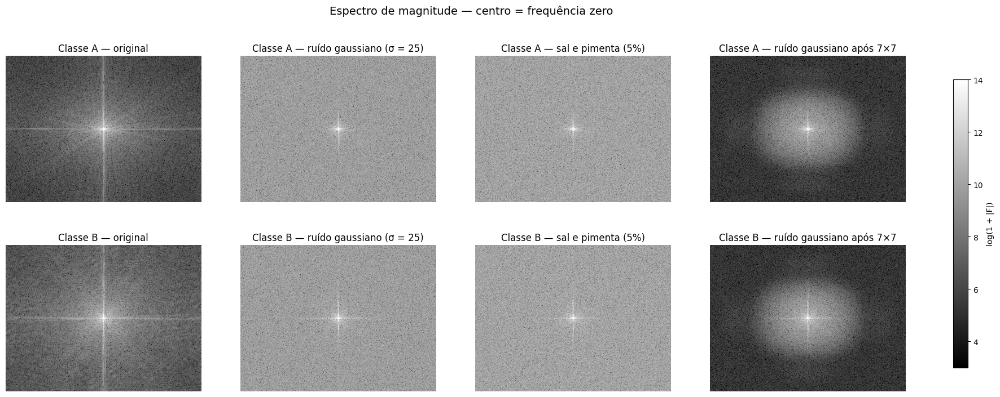

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for linha, chave in enumerate(imagens):
    versoes = [('original', imagens[chave]),
               (f'ruído gaussiano (σ = {SIGMA_PRINCIPAL})', ruido_g[(chave, SIGMA_PRINCIPAL)]),
               (f'sal e pimenta ({DENSIDADE_PRINCIPAL:.0%})', ruido_sp[(chave, DENSIDADE_PRINCIPAL)]),
               ('ruído gaussiano após 7×7',
                para_uint8(filtrar_frequencia(ruido_g[(chave, SIGMA_PRINCIPAL)], H[7])[0]))]
    for col, (rotulo, img) in enumerate(versoes):
        mapa = axes[linha, col].imshow(espectro(img), cmap='gray', vmin=3, vmax=14)
        axes[linha, col].set_title(f'{chave} — {rotulo}')
        axes[linha, col].axis('off')
fig.colorbar(mapa, ax=axes, fraction=0.015, label='log(1 + |F|)')
fig.suptitle('Espectro de magnitude — centro = frequência zero', fontsize=14)
plt.show()

Kernel 3×3: ganho 0,5 em 0.250 ciclos/pixel
Kernel 7×7: ganho 0,5 em 0.134 ciclos/pixel


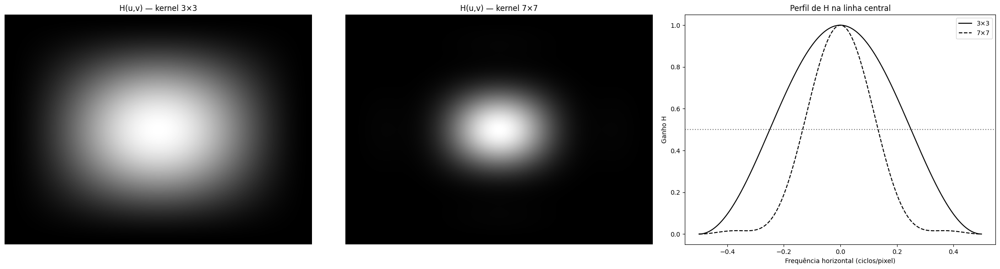

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
freqs = np.fft.fftshift(np.fft.fftfreq(formato[1]))      # ciclos/pixel na horizontal
estilos = {3: '-', 7: '--'}
for col, k in enumerate(KERNELS):
    Hc = np.fft.fftshift(H[k].real)
    axes[col].imshow(Hc, cmap='gray', vmin=0, vmax=1)
    axes[col].set_title(f'H(u,v) — kernel {k}×{k}')
    axes[col].axis('off')
    axes[2].plot(freqs, Hc[formato[0] // 2], color='black', ls=estilos[k], label=f'{k}×{k}')
    meia = freqs[freqs >= 0][np.argmin(np.abs(Hc[formato[0] // 2][freqs >= 0] - 0.5))]
    print(f'Kernel {k}×{k}: ganho 0,5 em {meia:.3f} ciclos/pixel')

axes[2].axhline(0.5, ls=':', color='gray')
axes[2].set_xlabel('Frequência horizontal (ciclos/pixel)')
axes[2].set_ylabel('Ganho H')
axes[2].set_title('Perfil de H na linha central')
axes[2].legend()
plt.tight_layout()
plt.show()

### 4.4 Aplicação dos kernels 3×3 e 7×7

Os dois filtros são aplicados às imagens com ruído gaussiano (σ = 25) e com sal e pimenta (5%) das duas classes. Métricas registradas:

- **PSNR e MAE** em relação à original: quanto a imagem filtrada se aproxima da imagem sem ruído;
- **desvio padrão na região lisa do fundo**: ruído residual. Para o ruído gaussiano, existe uma previsão teórica: um filtro linear com pesos $w_i$ reduz o desvio de ruído independente para $\sigma \sqrt{\sum w_i^2}$;
- **Canny e Otsu**: os mesmos testes das Seções 3.1 e 3.2, para verificar se o filtro recupera o desempenho dos algoritmos.

In [ ]:
filtradas = {}   # filtradas[(classe, ruido, k)] -> imagem uint8
linhas = []

versoes_ruido = {'Gaussiano σ = 25': ruido_g, 'Sal e pimenta 5%': ruido_sp}
parametro = {'Gaussiano σ = 25': SIGMA_PRINCIPAL, 'Sal e pimenta 5%': DENSIDADE_PRINCIPAL}

for chave, img in imagens.items():
    for nome_ruido, dicionario in versoes_ruido.items():
        ruidosa = dicionario[(chave, parametro[nome_ruido])]
        for k in [0] + KERNELS:                    # k = 0: sem filtro (referência)
            saida = ruidosa if k == 0 else para_uint8(filtrar_frequencia(ruidosa, H[k])[0])
            filtradas[(chave, nome_ruido, k)] = saida
            _, _, medidas = avaliar_algoritmos(saida)
            previsto = SIGMA_PRINCIPAL * np.sqrt((kernel_gaussiano(k) ** 2).sum()) if k else SIGMA_PRINCIPAL
            linhas.append({
                'Classe': chave, 'Ruído': nome_ruido, 'Filtro': 'sem filtro' if k == 0 else f'{k}×{k}',
                'PSNR (dB)': round(psnr(img, saida), 2),
                'MAE': round(mae(img, saida), 2),
                'Desvio no fundo liso': round(float(recorte(saida, REGIOES[chave]['fundo']).std()), 2),
                'Desvio previsto (gaussiano)': round(previsto, 2) if nome_ruido.startswith('Gauss') else '—',
                **medidas,
            })

tabela_filtros = pd.DataFrame(linhas).set_index(['Classe', 'Ruído', 'Filtro'])
tabela_filtros

PSNR (dB)    MAE  Desvio no fundo liso  \
Classe   Ruído            Filtro                                               
Classe A Gaussiano σ = 25 sem filtro      20.21  19.89                 24.83   
                          3×3             28.65   7.51                  9.31   
                          7×7             33.49   4.21                  4.94   
         Sal e pimenta 5% sem filtro      18.23   6.39                 33.40   
                          3×3             26.48   5.99                 12.53   
                          7×7             31.01   4.85                  6.76   
Classe B Gaussiano σ = 25 sem filtro      20.25  19.84                 24.44   
                          3×3             28.53   7.57                  9.14   
                          7×7             32.38   4.46                  4.82   
         Sal e pimenta 5% sem filtro      18.04   6.38                 34.41   
                          3×3             26.15   6.16                 12.90   
                          7×7             30.03   5.26                  6.93   

                                     Desvio previsto (gaussiano)  \
Classe   Ruído            Filtro                                   
Classe A Gaussiano σ = 25 sem filtro                          25   
                          3×3                               9.38   
                          7×7                               5.02   
         Sal e pimenta 5% sem filtro                           —   
                          3×3                                  —   
                          7×7                                  —   
Classe B Gaussiano σ = 25 sem filtro                          25   
                          3×3                               9.38   
                          7×7                               5.02   
         Sal e pimenta 5% sem filtro                           —   
                          3×3                                  —   
                          7×7                                  —   

                                      Pixels de borda — Canny (%)  \
Classe   Ruído            Filtro                                    
Classe A Gaussiano σ = 25 sem filtro                        36.25   
                          3×3                               27.57   
                          7×7                                0.32   
         Sal e pimenta 5% sem filtro                        24.25   
                          3×3                               18.75   
                          7×7                                0.61   
Classe B Gaussiano σ = 25 sem filtro                        36.27   
                          3×3                               27.27   
                          7×7                                0.54   
         Sal e pimenta 5% sem filtro                        23.67   
                          3×3                               18.48   
                          7×7                                0.97   

                                      Limiar de Otsu  \
Classe   Ruído            Filtro                       
Classe A Gaussiano σ = 25 sem filtro             124   
                          3×3                    116   
                          7×7                    117   
         Sal e pimenta 5% sem filtro             109   
                          3×3                    118   
                          7×7                    117   
Classe B Gaussiano σ = 25 sem filtro             132   
                          3×3                    129   
                          7×7                    130   
         Sal e pimenta 5% sem filtro             124   
                          3×3                    130   
                          7×7                    130   

                                      Regiões segmentadas — Otsu  
Classe   Ruído            Filtro                                  
Classe A Gaussiano σ = 25 sem filtro                       11370  
           

### 4.5 Visualização: original → ruído → 3×3 → 7×7

Três figuras:

1. Sequência completa para o **ruído gaussiano**;
2. Sequência completa para o **sal e pimenta**;
3. **Recortes ampliados** do fundo e do detalhe, com os dois ruídos e os dois kernels lado a lado.

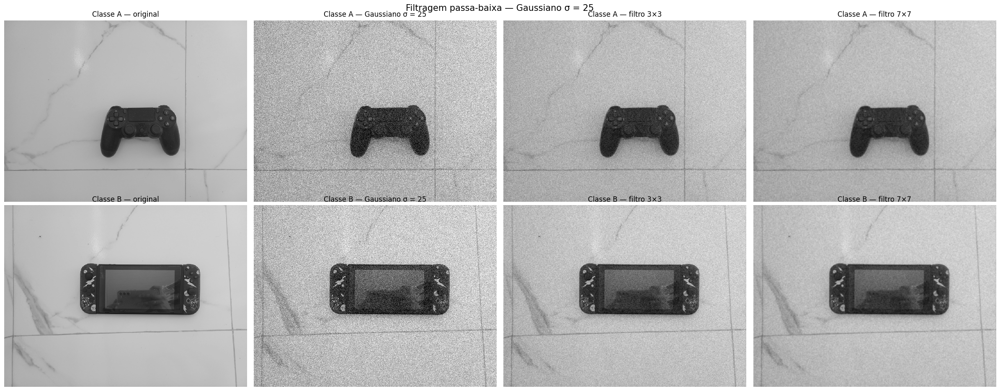

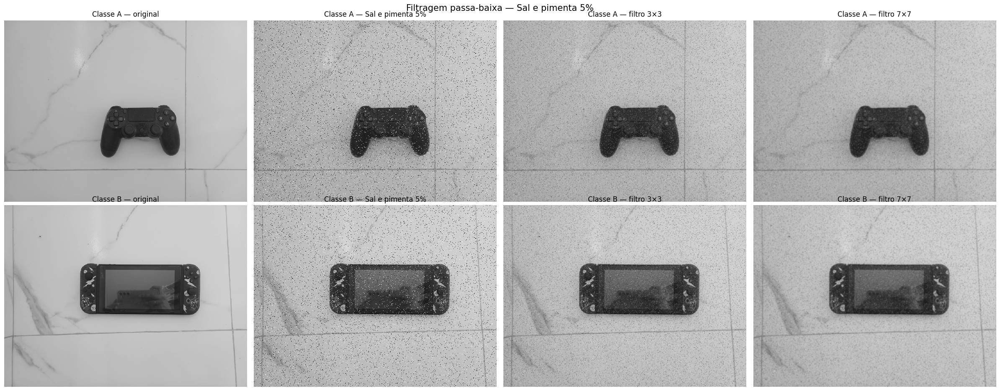

In [ ]:
for nome_ruido in versoes_ruido:
    fig, axes = plt.subplots(2, 4, figsize=(24, 9.5))
    for linha, chave in enumerate(imagens):
        sequencia = [('original', imagens[chave]),
                     (f'{nome_ruido}', filtradas[(chave, nome_ruido, 0)]),
                     ('filtro 3×3', filtradas[(chave, nome_ruido, 3)]),
                     ('filtro 7×7', filtradas[(chave, nome_ruido, 7)])]
        for col, (rotulo, img) in enumerate(sequencia):
            axes[linha, col].imshow(img, cmap='gray', vmin=0, vmax=255)
            axes[linha, col].set_title(f'{chave} — {rotulo}')
            axes[linha, col].axis('off')
    plt.suptitle(f'Filtragem passa-baixa — {nome_ruido}', fontsize=15)
    plt.tight_layout()
    plt.show()

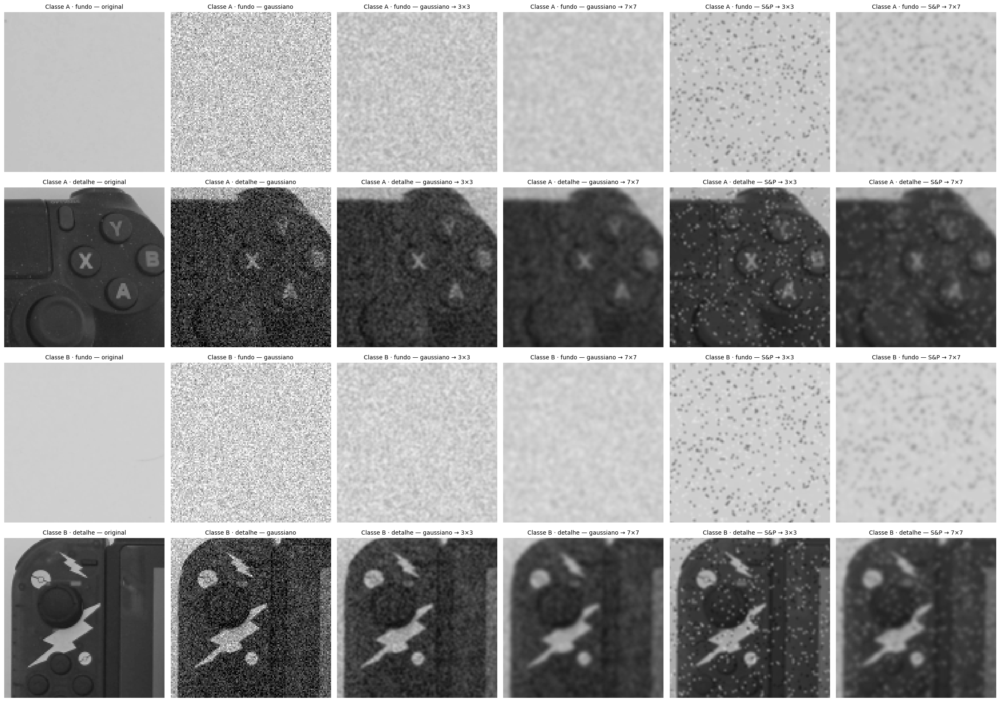

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(24, 17))
for i, chave in enumerate(imagens):
    for j, nome_regiao in enumerate(['fundo', 'detalhe']):
        lin = 2 * i + j
        regiao = REGIOES[chave][nome_regiao]
        versoes = [('original', imagens[chave]),
                   ('gaussiano', filtradas[(chave, 'Gaussiano σ = 25', 0)]),
                   ('gaussiano → 3×3', filtradas[(chave, 'Gaussiano σ = 25', 3)]),
                   ('gaussiano → 7×7', filtradas[(chave, 'Gaussiano σ = 25', 7)]),
                   ('S&P → 3×3', filtradas[(chave, 'Sal e pimenta 5%', 3)]),
                   ('S&P → 7×7', filtradas[(chave, 'Sal e pimenta 5%', 7)])]
        for col, (rotulo, img) in enumerate(versoes):
            axes[lin, col].imshow(recorte(img, regiao), cmap='gray', vmin=0, vmax=255)
            axes[lin, col].set_title(f'{chave} · {nome_regiao} — {rotulo}', fontsize=10)
            axes[lin, col].axis('off')
plt.tight_layout()
plt.show()

### 4.6 Custo do filtro: o que se perde na imagem sem ruído

Na imagem ruidosa, o efeito do filtro mistura duas coisas: a remoção do ruído e a perda de detalhe. Para isolar a **perda de detalhe**, os mesmos filtros são aplicados à imagem **original, sem ruído**. Tudo o que muda nesse caso é custo, porque não havia ruído para remover. Medidas:

- **gradiente médio (Sobel) na região de detalhe**, em % do original: quanto da nitidez das bordas foi preservado;
- **contraste Δ** das letras do controle e das estampas do Switch, com as mesmas máscaras da Seção 3.1.

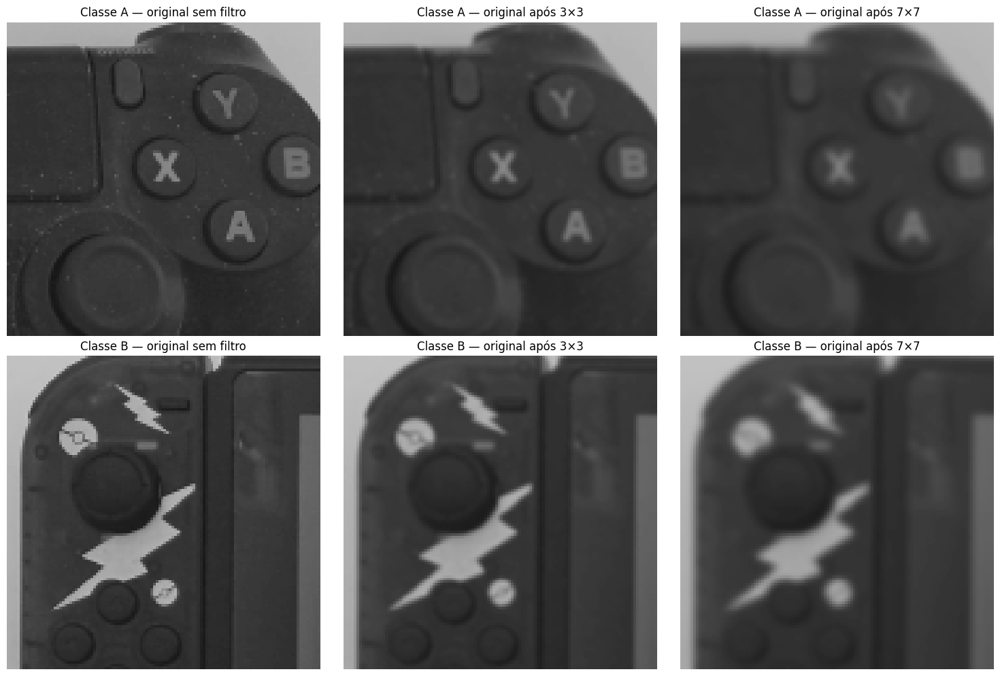

PSNR vs. original (dB)  Gradiente preservado (%)  \
Classe   Filtro                                                        
Classe A sem filtro                      —                     100.0   
         3×3                         47.04                      82.2   
         7×7                         42.27                      65.3   
Classe B sem filtro                      —                     100.0   
         3×3                         41.61                      87.3   
         7×7                         37.13                      74.4   

                     Contraste Δ do detalhe  
Classe   Filtro                              
Classe A sem filtro                    49.5  
         3×3                           48.0  
         7×7                           45.0  
Classe B sem filtro                   120.0  
         3×3                          115.5  
         7×7                          109.0

In [ ]:
def gradiente_medio(img):
    x = img.astype(np.float64)
    return np.hypot(cv2.Sobel(x, cv2.CV_64F, 1, 0), cv2.Sobel(x, cv2.CV_64F, 0, 1)).mean()

# posições das letras (A) e das estampas (B) na região de detalhe da original
mascaras_detalhe = {
    'Classe A': (det_A < 80, (det_A >= 80) & (det_A < 130)),
    'Classe B': (det_B < 80, det_B > 150),
}

linhas = []
limpas = {}
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for linha, chave in enumerate(imagens):
    img = imagens[chave]
    corpo, detalhe = mascaras_detalhe[chave]
    grad_ref = gradiente_medio(recorte(img, REGIOES[chave]['detalhe']))
    for col, k in enumerate([0] + KERNELS):
        saida = img if k == 0 else para_uint8(filtrar_frequencia(img, H[k])[0])
        limpas[(chave, k)] = saida
        reg = recorte(saida, REGIOES[chave]['detalhe']).astype(np.float64)
        linhas.append({
            'Classe': chave, 'Filtro': 'sem filtro' if k == 0 else f'{k}×{k}',
            'PSNR vs. original (dB)': '—' if k == 0 else round(psnr(img, saida), 2),
            'Gradiente preservado (%)': round(100 * gradiente_medio(reg) / grad_ref, 1),
            'Contraste Δ do detalhe': round(np.median(reg[detalhe]) - np.median(reg[corpo]), 1),
        })
        axes[linha, col].imshow(reg, cmap='gray', vmin=0, vmax=255)
        axes[linha, col].set_title(f'{chave} — original ' + ('sem filtro' if k == 0 else f'após {k}×{k}'))
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

pd.DataFrame(linhas).set_index(['Classe', 'Filtro'])

### 4.7 Impacto nos algoritmos

Bordas detectadas pelo Canny (limiares 50 e 150, os mesmos das seções anteriores) na original e nas imagens filtradas. Os valores numéricos, incluindo o Otsu, estão na tabela da Seção 4.4.

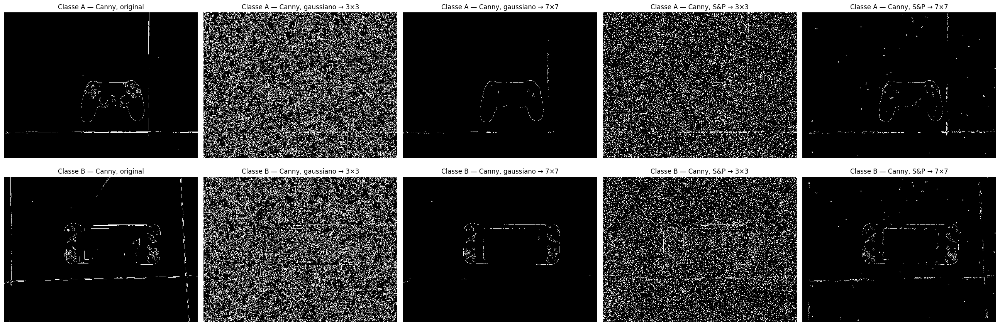

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(26, 9))
for linha, chave in enumerate(imagens):
    versoes = [('original', imagens[chave]),
               ('gaussiano → 3×3', filtradas[(chave, 'Gaussiano σ = 25', 3)]),
               ('gaussiano → 7×7', filtradas[(chave, 'Gaussiano σ = 25', 7)]),
               ('S&P → 3×3', filtradas[(chave, 'Sal e pimenta 5%', 3)]),
               ('S&P → 7×7', filtradas[(chave, 'Sal e pimenta 5%', 7)])]
    for col, (rotulo, img) in enumerate(versoes):
        axes[linha, col].imshow(cv2.Canny(img, 50, 150), cmap='gray')
        axes[linha, col].set_title(f'{chave} — Canny, {rotulo}')
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

### 4.8 Interpretação

**1. O filtro conseguiu reduzir o ruído?**

* **Ruído gaussiano: sim.** No espectro, o ruído espalha energia de maneira uniforme por todas as frequências; depois do 7×7, as altas frequências voltam a ficar escuras, mas permanece um halo ao redor do centro, formado pela parte do ruído que ocupa as mesmas baixas frequências da cena e que nenhum passa-baixa consegue separar dela (o formato elíptico se deve apenas à proporção 4:3 da imagem). A redução acompanha a previsão teórica de um filtro de média ponderada, σ·√Σw²: na Classe A, o desvio no fundo liso caiu de 24,83 para 9,31 (3×3) e 4,94 (7×7), muito próximo dos valores previstos (9,38 e 5,02). O PSNR subiu de 20,21 para 28,65 e 33,49 dB.
* **Sal e pimenta: não de fato.** O filtro gaussiano não ignora valores extremos: faz a média deles com os vizinhos e converte os pontos pretos e brancos em manchas acinzentadas difusas. O MAE tem queda modesta (6,39 → 4,85 na Classe A, com 7×7), porque o erro é apenas redistribuído. O PSNR sobe de 18,23 para 31,01 dB porque, baseado no erro quadrático, favorece trocar poucos erros grandes por muitos pequenos. Para esse ruído, o indicado seria um filtro não linear, como a mediana.

**2. Que detalhes da imagem foram perdidos?** O custo fica isolado ao aplicar os filtros às imagens **sem ruído**. A nitidez das bordas na região de detalhe cai para 82% (3×3) e 65% (7×7) na Classe A, e para 87% e 74% na Classe B, que perde menos porque seus detalhes principais, as estampas, são grandes e de alto contraste. Visualmente, o 7×7 apaga os pontos finos de poeira no plástico do controle, suaviza as bordas das letras dos botões (que continuam legíveis, com contraste praticamente mantido: 49,5 → 45) e das estampas, e elimina a linha interna das pokébolas. No Canny das imagens filtradas, a silhueta dos objetos sobrevive, mas os veios do mármore, a maior parte dos rejuntes e os contornos internos dos botões desaparecem.

**3. Qual kernel apresentou melhor equilíbrio entre suavização e preservação de detalhes?** Para o nível de ruído testado (σ = 25), o **7×7**. Sua máscara começa a cortar numa frequência mais baixa (ganho 0,5 em 0,134 ciclo/pixel, contra 0,250 no 3×3). O 3×3 preserva mais nitidez, mas deixa passar o ruído de frequências médias: a imagem continua granulada, o Canny ainda marca 27,57% dos pixels como borda (Classe A) e o Otsu gera 81 regiões em A e 214 em B (contra 4 e 39 na original). O 7×7 reduz os pixels de borda a 0,32% (A) e 0,54% (B), devolve uma segmentação próxima da original (5 em A; 24 em B) e recupera o contorno dos objetos, ao custo de cerca de um terço da nitidez.

## 5. Filtragem passa-alta no domínio da frequência

### 5.1 Conceito

Um **filtro passa-alta** faz o oposto do passa-baixa: atenua as baixas frequências (regiões homogêneas, variações lentas de iluminação) e preserva ou amplifica as altas (bordas, contornos, texturas finas). Onde a imagem é lisa, a resposta é próxima de zero; onde a intensidade muda bruscamente, a resposta é forte.

| | Passa-baixa (Seção 4) | Passa-alta (Seção 5) |
|---|---|---|
| Máscara H(u,v) | ~1 no centro, → 0 nas bordas do espectro | 0 no centro, forte nas bordas do espectro |
| No espaço | média ponderada da vizinhança | diferença entre o pixel e seus vizinhos |
| Efeito | suaviza, reduz ruído, perde detalhe | realça bordas e detalhes, **amplifica ruído** |

**Laplaciano.** É a soma das segundas derivadas nas duas direções, $\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$. Na versão discreta com 4 vizinhos, compara cada pixel com a soma dos vizinhos acima, abaixo e aos lados:

$$\nabla^2 f(x,y) = f(x{+}1,y) + f(x{-}1,y) + f(x,y{+}1) + f(x,y{-}1) - 4f(x,y) \quad\Longleftrightarrow\quad \begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$$

- **Por que destaca bordas:** numa região uniforme, o pixel é igual à média dos vizinhos e a resposta é zero. A resposta também é zero numa rampa suave de intensidade, porque a segunda derivada ignora variações lineares. Ela só é forte onde a *taxa* de variação muda de repente, que é exatamente o que acontece numa borda.
- **Borda dupla:** ao atravessar uma borda, a resposta é positiva de um lado e negativa do outro, e cruza o zero na posição exata da borda. Por isso o resultado tem sinal, e a forma de exibição importa: com sinal (cores divergentes), em magnitude $|\nabla^2 f|$ ou somado à imagem para realçá-la.

**Máscara na frequência.** Pela mesma técnica da Seção 4 (FFT do kernel), a máscara do Laplaciano de 4 vizinhos é

$$H(u,v) = 2\cos\!\left(\tfrac{2\pi u}{M}\right) + 2\cos\!\left(\tfrac{2\pi v}{N}\right) - 4$$

que vale **0 na frequência zero** (o brilho médio é eliminado) e chega a **−8 nas frequências mais altas**: uma máscara passa-alta.

**Alternativas.** A versão contínua $H = -4\pi^2 D^2(u,v)$ é a mais citada em livros, mas cresce sem limite com a frequência e exige normalizar $D$ para produzir valores comparáveis. Um passa-alta gaussiano ($1 - H_{\text{passa-baixa}}$) é mais suave e amplifica menos o ruído, mas não é um detector de bordas clássico. Foi usado o Laplaciano de 4 vizinhos, porque é o "Laplaciano" sugerido no PDF, tem a máscara exata derivada do kernel (como na Seção 4) e pode ser verificado contra o `cv2.Laplacian`.

**Realce.** Somar o passa-alta à imagem acentua suas bordas. Como o centro do kernel é negativo, o realce é $g = f - \nabla^2 f$.

### 5.2 Implementação e verificação

O filtro é aplicado com as mesmas funções da Seção 4 (`filtrar_frequencia`). A verificação compara o resultado com o `cv2.Laplacian(ksize=1)`, que usa exatamente esse kernel no espaço. Como antes, a diferença só pode aparecer na margem da imagem, onde a FFT considera a imagem periódica.

In [ ]:
KERNEL_LAPLACIANO = np.array([[0, 1, 0],
                              [1, -4, 1],
                              [0, 1, 0]], dtype=np.float64)

def mascara_de(kernel, formato):
    # Máscara H(u,v) exata de um kernel qualquer (mesma ideia de mascara_do_kernel da Seção 4)
    k = kernel.shape[0]
    P = np.zeros(formato)
    P[:k, :k] = kernel
    return np.fft.fft2(np.roll(P, (-(k // 2), -(k // 2)), axis=(0, 1)))

H_lap = mascara_de(KERNEL_LAPLACIANO, formato)

def laplaciano(img):
    return filtrar_frequencia(img, H_lap)[0]      # resultado COM sinal (float)

print(f'H do Laplaciano: mínimo {H_lap.real.min():.2f}, máximo {H_lap.real.max():.2f}, '
      f'parte imaginária máx. {np.abs(H_lap.imag).max():.1e}')

ref = cv2.Laplacian(imagens['Classe A'].astype(np.float64), cv2.CV_64F, ksize=1)
dif = np.abs(laplaciano(imagens['Classe A']) - ref)
print(f'Máx. |frequência − cv2.Laplacian| no interior: {dif[1:-1, 1:-1].max():.1e}')
print(f'Máx. |frequência − cv2.Laplacian| na margem:   {dif.max():.1f}')

H do Laplaciano: mínimo -8.00, máximo 0.00, parte imaginária máx. 8.4e-16
Máx. |frequência − cv2.Laplacian| no interior: 2.3e-13
Máx. |frequência − cv2.Laplacian| na margem:   75.0


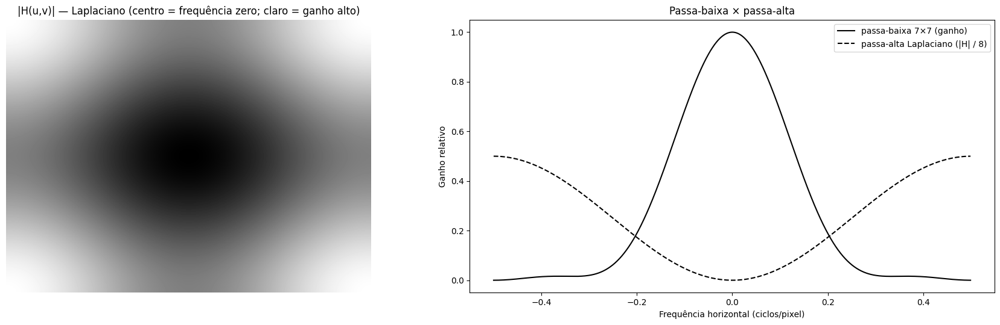

In [ ]:
# Máscaras passa-baixa e passa-alta lado a lado (linha central do espectro)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
Hc_lap = np.fft.fftshift(H_lap.real)
axes[0].imshow(np.abs(Hc_lap), cmap='gray')
axes[0].set_title('|H(u,v)| — Laplaciano (centro = frequência zero; claro = ganho alto)')
axes[0].axis('off')

centro = formato[0] // 2
axes[1].plot(freqs, np.fft.fftshift(H[7].real)[centro], color='black', ls='-', label='passa-baixa 7×7 (ganho)')
axes[1].plot(freqs, np.abs(Hc_lap[centro]) / 8, color='black', ls='--', label='passa-alta Laplaciano (|H| / 8)')
axes[1].set_xlabel('Frequência horizontal (ciclos/pixel)')
axes[1].set_ylabel('Ganho relativo')
axes[1].set_title('Passa-baixa × passa-alta')
axes[1].legend()
plt.tight_layout()
plt.show()

### 5.3 Visualização: original × passa-alta

1. **Imagem inteira:** original × magnitude do Laplaciano, com a **mesma escala** (0 a 40) nas duas classes, para que as respostas sejam comparáveis;
2. **Recortes ampliados** da região de detalhe: original, Laplaciano com sinal (cinza médio = zero, claro = positivo, escuro = negativo), magnitude e imagem realçada ($f - \nabla^2 f$);
3. **Região do reflexo especular** no piso, com contraste esticado, e seu Laplaciano.

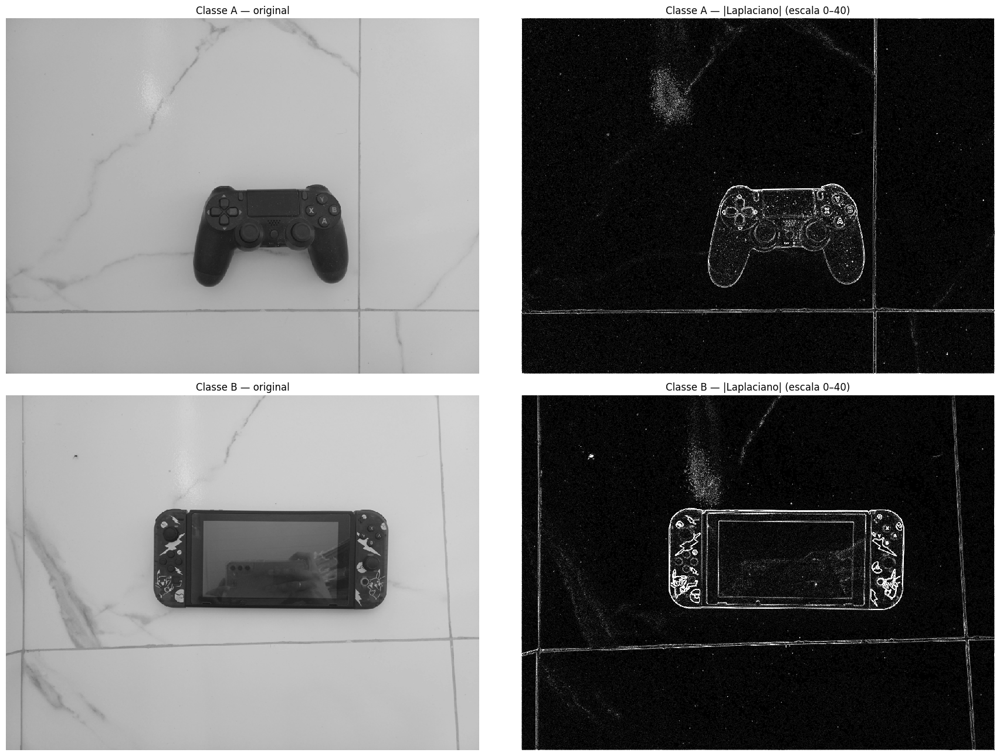

In [ ]:
ESCALA_LAP = 40
resposta = {chave: laplaciano(img) for chave, img in imagens.items()}

fig, axes = plt.subplots(2, 2, figsize=(18, 13))
for linha, chave in enumerate(imagens):
    axes[linha, 0].imshow(imagens[chave], cmap='gray', vmin=0, vmax=255)
    axes[linha, 0].set_title(f'{chave} — original')
    axes[linha, 1].imshow(np.abs(resposta[chave]), cmap='gray', vmin=0, vmax=ESCALA_LAP)
    axes[linha, 1].set_title(f'{chave} — |Laplaciano| (escala 0–{ESCALA_LAP})')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

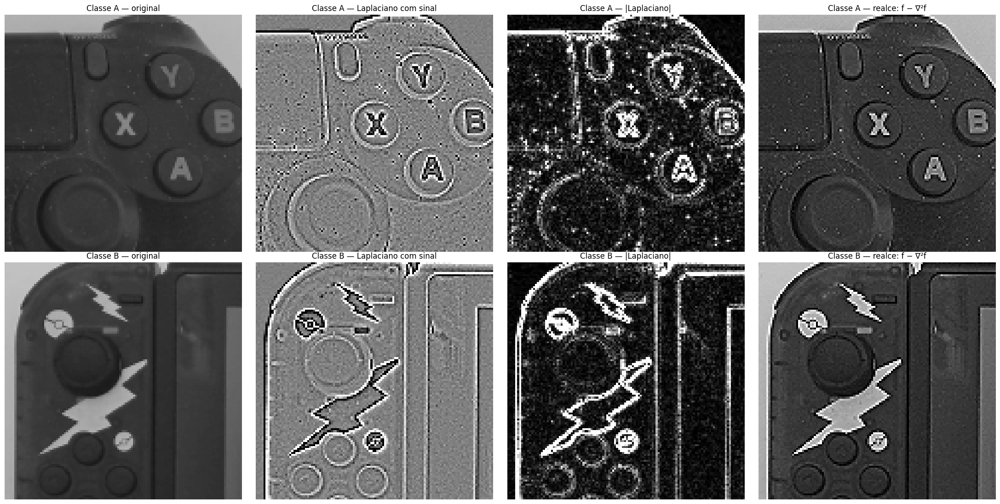

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
for linha, chave in enumerate(imagens):
    regiao = REGIOES[chave]['detalhe']
    L = resposta[chave]
    paineis = [('original', imagens[chave], dict(cmap='gray', vmin=0, vmax=255)),
               ('Laplaciano com sinal', L, dict(cmap='gray', vmin=-ESCALA_LAP, vmax=ESCALA_LAP)),
               ('|Laplaciano|', np.abs(L), dict(cmap='gray', vmin=0, vmax=ESCALA_LAP)),
               ('realce: f − ∇²f', np.clip(imagens[chave] - L, 0, 255), dict(cmap='gray', vmin=0, vmax=255))]
    for col, (rotulo, img, estilo) in enumerate(paineis):
        axes[linha, col].imshow(recorte(img, regiao), **estilo)
        axes[linha, col].set_title(f'{chave} — {rotulo}')
        axes[linha, col].axis('off')
plt.tight_layout()
plt.show()

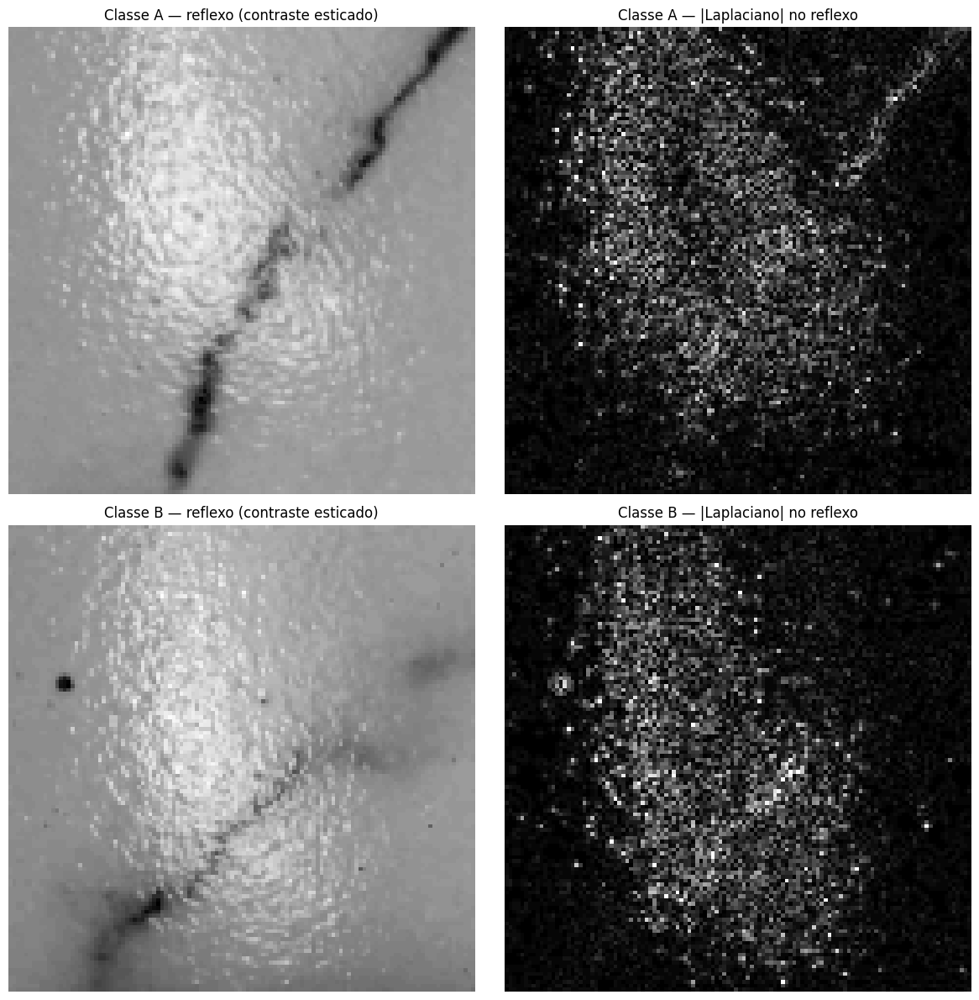

In [ ]:
# Região do reflexo especular no piso (janela de maior resposta no fundo superior de cada imagem)
REGIAO_REFLEXO = {'Classe A': (124, 244, 268, 388), 'Classe B': (124, 244, 340, 460)}

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for linha, chave in enumerate(imagens):
    reg = recorte(imagens[chave], REGIAO_REFLEXO[chave]).astype(np.float64)
    esticada = (reg - reg.min()) / (reg.max() - reg.min()) * 255      # contraste esticado só para exibir
    axes[linha, 0].imshow(esticada, cmap='gray', vmin=0, vmax=255)
    axes[linha, 0].set_title(f'{chave} — reflexo (contraste esticado)')
    axes[linha, 1].imshow(np.abs(recorte(resposta[chave], REGIAO_REFLEXO[chave])), cmap='gray', vmin=0, vmax=ESCALA_LAP)
    axes[linha, 1].set_title(f'{chave} — |Laplaciano| no reflexo')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.4 Onde está a resposta?

A imagem é dividida em três regiões, a partir da silhueta do objeto (maior região escura, com os buracos internos preenchidos):

- **contorno:** faixa de 5 px ao longo da borda externa do objeto;
- **interior:** o restante do objeto (botões, letras, estampas, tela);
- **fundo:** o piso (veios, rejuntes, reflexo).

Para cada região, são medidas a resposta média $|\nabla^2 f|$ e a fração dos **1% pixels de resposta mais forte** da imagem que cai nela. Também são medidas a resposta no reflexo e no fundo liso, e a **variância do Laplaciano** da imagem inteira, que indica a quantidade total de alta frequência (bordas e detalhes).

In [ ]:
def regioes_objeto(img):
    mascara = ((img < 110) * 255).astype(np.uint8)
    n, rotulos, stats, _ = cv2.connectedComponentsWithStats(mascara)
    maior = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    contornos, _ = cv2.findContours(((rotulos == maior) * 255).astype(np.uint8),
                                    cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    silhueta = np.zeros(img.shape, np.uint8)
    cv2.drawContours(silhueta, contornos, -1, 255, thickness=-1)           # preenche buracos
    faixa = cv2.morphologyEx(silhueta, cv2.MORPH_GRADIENT, np.ones((5, 5), np.uint8)) > 0
    silhueta = silhueta > 0
    return {'contorno': faixa, 'interior': silhueta & ~faixa, 'fundo': ~silhueta & ~faixa}

linhas = []
for chave, img in imagens.items():
    mag = np.abs(resposta[chave])
    fortes = mag >= np.percentile(mag, 99)
    reg = regioes_objeto(img)
    linha = {'Classe': chave}
    for nome, m in reg.items():
        linha[f'Área {nome} (%)'] = round(100 * m.mean(), 1)
        linha[f'|∇²f| médio — {nome}'] = round(mag[m].mean(), 2)
        linha[f'Dos 1% mais fortes — {nome} (%)'] = round(100 * (fortes & m).sum() / fortes.sum(), 1)
    linha['|∇²f| médio — reflexo'] = round(recorte(mag, REGIAO_REFLEXO[chave]).mean(), 2)
    linha['|∇²f| médio — fundo liso'] = round(recorte(mag, REGIOES[chave]['fundo']).mean(), 2)
    linha['Variância do Laplaciano'] = round(resposta[chave].var(), 1)
    linhas.append(linha)

pd.DataFrame(linhas).set_index('Classe').T

Classe,Classe A,Classe B
Área contorno (%),0.70,0.80
|∇²f| médio — contorno,18.42,34.53
Dos 1% mais fortes — contorno (%),20.60,32.80
Área interior (%),6.20,13.00
|∇²f| médio — interior,6.32,7.89
Dos 1% mais fortes — interior (%),28.30,56.60
Área fundo (%),93.10,86.20
|∇²f| médio — fundo,1.67,1.69
Dos 1% mais fortes — fundo (%),51.10,10.50
|∇²f| médio — reflexo,5.12,4.68


### 5.5 Interpretação

**1. Que estruturas da imagem foram destacadas?** O filtro Laplaciano escurece as regiões homogêneas e evidencia as áreas com variações bruscas de intensidade. Ficam destacados o contorno externo dos objetos, os detalhes internos (letras, botões e analógicos do controle; estampas, pokébolas e moldura da tela do Switch) e as estruturas do fundo, como os rejuntes e os veios do mármore. Um resultado notável ocorre na região do reflexo especular, que exibe uma microtextura granular imperceptível na imagem original: com o contraste esticado, o recorte mostra que se trata do relevo da superfície do piso, visível apenas onde a luz é refletida diretamente para a câmera. Nessa região, a magnitude média do Laplaciano é de 4 a 5 vezes a do fundo liso (5,12 contra 1,16 em A; 4,68 contra 0,93 em B).

As classes diferem na distribuição da resposta. Nas duas, a magnitude média é máxima no contorno externo (18,42 em A; 34,53 em B), mas os 1% pixels de resposta mais forte se concentram em lugares diferentes: no **controle**, cujos detalhes internos têm baixo contraste, as estruturas do piso concentram 51,1% deles; no **Switch**, as estampas brancas concentram 56,6% no interior do aparelho. A variância do Laplaciano, que reflete a quantidade de alta frequência, é quase quatro vezes maior no Switch (96,4 contra 25,6), impulsionada principalmente pelas estampas.

**2. As bordas ficaram mais visíveis?** Sim. O filtro responde à nitidez da transição de intensidade, e não ao contraste absoluto, o que torna as bordas proeminentes mesmo em detalhes de baixo contraste, como as letras do controle. Na visualização com sinal, a natureza de segunda derivada fica clara: cada borda aparece dupla, com uma faixa clara de um lado e uma escura do outro, cruzando o zero (cinza médio) no limite da borda. Quando a imagem é realçada subtraindo o Laplaciano (f − ∇²f), as letras e as estampas ganham definição, mas o processo também amplifica frequências indesejadas, gerando halos claros ao redor dos objetos e acentuando as partículas de poeira.

**3. Esse tipo de filtro ajudaria em quais tarefas de Visão Computacional?**

* **Detecção de bordas:** localização dos limites dos objetos pelos cruzamentos por zero, como base para a segmentação.
* **Análise estrutural:** extração de linhas contínuas, como os rejuntes, para a transformada de Hough na estimativa da geometria da cena.
* **Medição de foco:** a variância do Laplaciano quantifica a nitidez; é o princípio usado em foco automático e no descarte de imagens borradas.
* **Inspeção de superfícies:** a detecção do relevo microscópico no reflexo mostra como o filtro pode revelar riscos e defeitos no controle de qualidade de superfícies polidas.
* **Pré-processamento para OCR:** o realce aumenta a nitidez dos caracteres, desde que a imagem não tenha ruído; caso contrário, é preciso suavizar antes, já que o passa-alta amplifica justamente as frequências em que o ruído está.

## 6. Comparação final

A figura reúne, para cada classe, as cinco etapas da tabela pedida no enunciado: original, os dois ruídos, a filtragem gaussiana (7×7, o kernel de melhor equilíbrio na Seção 4) e o filtro passa-alta aplicado à original.

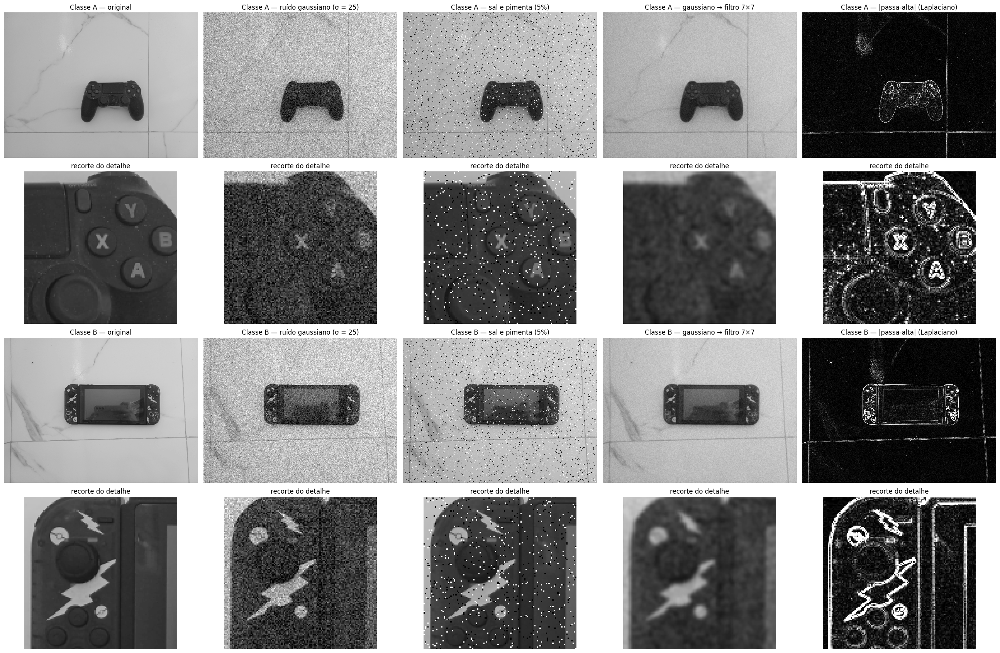

In [ ]:
etapas = lambda chave: [
    ('original', imagens[chave], 255),
    (f'ruído gaussiano (σ = {SIGMA_PRINCIPAL})', ruido_g[(chave, SIGMA_PRINCIPAL)], 255),
    (f'sal e pimenta ({DENSIDADE_PRINCIPAL:.0%})', ruido_sp[(chave, DENSIDADE_PRINCIPAL)], 255),
    ('gaussiano → filtro 7×7', filtradas[(chave, 'Gaussiano σ = 25', 7)], 255),
    ('|passa-alta| (Laplaciano)', np.abs(resposta[chave]), ESCALA_LAP),
]

fig, axes = plt.subplots(4, 5, figsize=(26, 17))
for i, chave in enumerate(imagens):
    for col, (rotulo, img, vmax) in enumerate(etapas(chave)):
        axes[2 * i, col].imshow(img, cmap='gray', vmin=0, vmax=vmax)
        axes[2 * i, col].set_title(f'{chave} — {rotulo}')
        axes[2 * i + 1, col].imshow(recorte(img, REGIOES[chave]['detalhe']), cmap='gray', vmin=0, vmax=vmax)
        axes[2 * i + 1, col].set_title('recorte do detalhe')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

### 6.1 Tabela de comparação

| Etapa | Classe A — Controle | Classe B — Nintendo Switch |
|---|---|---|
| **Imagem original** | Controle escuro sobre piso claro; detalhes internos de baixo contraste (letras: Δ ≈ 50). Fundo praticamente sem ruído (desvio ~0,8). Canny: 0,88% de pixels de borda; Otsu: 4 regiões. | Switch escuro sobre o mesmo piso; estampas de alto contraste (Δ ≈ 120) e reflexo na tela. Fundo sem ruído (desvio ~0,7). Canny: 1,39%; Otsu: 39 regiões. |
| **Ruído gaussiano (σ = 25)** | Granulação em toda a imagem (98,4% dos pixels alterados). Letras Y e B quase somem. PSNR 20,2 dB; Canny 36,3%; Otsu 11.370 regiões. | Mesma granulação, mas as estampas continuam nítidas. PSNR 20,3 dB; Canny 36,3%; Otsu 9.950 regiões. |
| **Ruído sal e pimenta (5%)** | Pontos isolados: pretos no piso, brancos no objeto; letras legíveis. PSNR 18,2 dB; Canny 24,3%; Otsu 16.572 regiões. | Mesmo padrão; a pimenta abre buracos nas estampas. PSNR 18,0 dB; Canny 23,7%; Otsu 15.387 regiões. |
| **Filtro gaussiano (7×7)** | Ruído gaussiano: granulação vira manchas leves (desvio no fundo 24,8 → 4,9; PSNR 33,5 dB; Otsu 5 regiões), com bordas mais suaves (65% da nitidez). Sal e pimenta: impulsos viram manchas cinzas (MAE 6,4 → 4,9). | Ruído gaussiano: PSNR 32,4 dB; Otsu 24 regiões; 74% da nitidez preservada. Sal e pimenta: mesmas manchas (MAE 6,4 → 5,3). |
| **Filtro passa-alta (Laplaciano)** | Destaca contorno, letras, botões, rejuntes, veios e a microtextura do reflexo; 51% das respostas mais fortes estão no piso. | Destaca contorno, estampas, pokébolas e moldura da tela; 57% das respostas mais fortes estão no interior do aparelho. |

### 6.2 Análise e respostas

**1. Qual ruído degradou mais a imagem?**

A avaliação depende do critério adotado, e as métricas divergem (valores da Classe A; a Classe B segue o mesmo padrão):

| Critério de avaliação | Gaussiano (σ = 25) | Sal e pimenta (5%) | Ruído mais prejudicial |
|---|---|---|---|
| Pixels alterados | 98,4% | 5,0% | Gaussiano |
| MAE | 19,9 | 6,4 | Gaussiano |
| PSNR | 20,2 dB | 18,2 dB | Sal e pimenta |
| Legibilidade das letras | Y e B quase ilegíveis | Preservada | Gaussiano |
| Falsas bordas (Canny) | 36,3% | 24,3% | Gaussiano |
| Fragmentação (Otsu) | 11.370 regiões | 16.572 regiões | Sal e pimenta |

* **Divergência entre métricas:** o PSNR baseia-se no erro quadrático médio (MSE) e penaliza severamente erros pontuais de alta amplitude, o perfil característico do sal e pimenta. Já o MAE e a percepção visual são mais sensíveis a pequenas perturbações distribuídas por toda a imagem, o que torna o ruído gaussiano visualmente mais degradante.
* **Impacto na segmentação:** no Otsu, cada ponto de pimenta sobre o piso claro fica abaixo do limiar global e é classificado como objeto, virando uma região isolada de um único pixel. O sal sobre o objeto escuro apenas abre buracos na máscara, sem criar novas regiões.
* **Conclusão:** para a leitura de detalhes finos e a detecção de bordas, o ruído gaussiano foi mais prejudicial; para a segmentação por limiarização global, o sal e pimenta causou maior degradação.

**2. O filtro gaussiano conseguiu recuperar a qualidade visual?**

Apenas parcialmente, e de forma seletiva.

* **Ruído gaussiano:** o kernel 7×7 obteve uma recuperação consistente: o PSNR subiu de ~20 dB para ~33 dB, a segmentação de Otsu voltou a uma contagem de regiões próxima da original e o Canny voltou a detectar o contorno dos objetos. A reconstrução, porém, não é perfeita: resta um padrão suave de manchas de baixa frequência, e cerca de um terço da nitidez das bordas é perdida (veios do mármore, rejuntes e linhas internas dos botões deixam de ser detectados). O kernel 3×3 foi insuficiente: manteve o aspecto granulado e um alto índice de falsas bordas (27,6% no Canny).
* **Ruído sal e pimenta:** o filtro linear falhou. Por fazer uma média ponderada da vizinhança, ele espalhou o erro de cada impulso, convertendo os pontos pretos e brancos em manchas cinzentas de menor amplitude, com queda apenas modesta do MAE (6,4 → 4,9). A eliminação desse padrão exige filtragem não linear, como o filtro de mediana.

**3. Em quais aplicações de Visão Computacional seria importante aplicar filtros antes do processamento?**

* **Inspeção industrial e controle de qualidade:** sem filtragem, o Canny marcou 36% dos pixels como borda; um sistema automatizado tenderia a classificar superfícies íntegras como defeituosas. Por outro lado, a suavização excessiva pode apagar microtrincas e imperfeições sutis, como o 7×7 apagou os veios finos do mármore, o que exige dimensionar o kernel com cuidado.
* **Segmentação e contagem de objetos:** o ruído elevou a contagem de regiões no Otsu de 4 para mais de 10.000. A suavização prévia é pré-requisito em sistemas de contagem de peças, de células em imagens biológicas ou de veículos.
* **Reconhecimento óptico de caracteres (OCR):** as letras de baixo contraste foram corrompidas pelo ruído gaussiano, e a suavização recuperou parcialmente a legibilidade. Em leitura de placas, rótulos e documentos, o filtro precisa ser dosado pelo tamanho dos caracteres.
* **Sensores ruidosos e transmissão sem fio:** câmeras em baixa iluminação (ISO alto) produzem principalmente ruído do tipo gaussiano, que pede suavização; pixels defeituosos e transmissões de vídeo sem fio produzem ruído impulsivo, que exige filtragem não linear antes da extração de características.
* **Autofoco e estimativa de nitidez:** filtros passa-alta, como o Laplaciano, amplificam o ruído, e a pré-suavização é necessária para estabilizar algoritmos de foco automático e de realce de bordas.

### 6.3 Fechamento

Os resultados evidenciam a sobreposição entre ruído e bordas nas altas frequências do espectro. Por atuarem sobre a mesma região do espectro, os filtros passa-baixa e passa-alta estabelecem um compromisso (*trade-off*): o passa-baixa atenua o ruído à custa da nitidez dos contornos, enquanto o passa-alta realça os detalhes à custa da amplificação do ruído. Nenhum filtro linear isolado separa perfeitamente o ruído dos detalhes finos da imagem.

A comparação entre as classes mostra que a sobrevivência dos detalhes é governada pelo seu contraste (Δ): as estampas do Nintendo Switch (Δ ≈ 120) permaneceram visíveis sob ruído e filtragem, enquanto as letras de baixo contraste do controle (Δ ≈ 50) foram rapidamente suprimidas. Em pipelines reais de Visão Computacional, o pré-processamento deve ser dimensionado considerando tanto o nível de ruído do sensor quanto o tamanho do menor detalhe de interesse.